In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.optim as optim
import os
import sklearn
import umap.umap_ as umap
from tqdm.notebook import tqdm

# 25.06

Посмотреть на реконтрукцию реального времени а не на рекнотрукцию плоского фроната и кривого фроната 

Сравнить и между собой (востарновление 2х вреимен против 1 времени) и между разынми моделями (рубцов, VAE )

In [2]:
import h5py
dt_params_rubsov_approximation_list = []
dt_params_list = []
h5_path = '/home3/rfit/Telescope_Array/phd_work/data/normed/Ivan_Kharuk_pr_ga_all_0001_eq_eff_normed_one_work_rubsov_approx.h5'
with h5py.File(h5_path, 'r') as f:
    print(f.keys())
    print(f['norm_param'].keys())
    print(f['norm_param']['recos'].keys())
    mean_recos = f['norm_param']['recos']['mean'][:]
    std_recos = f['norm_param']['recos']['std'][:]
    mc_params = f['test']['mc_params'][:]

    mean_dt_params = f['norm_param']['dt_params']['mean'][:]
    std_dt_params = f['norm_param']['dt_params']['std'][:]
    if 'dt_params_rubsov_approximation' in f['test'].keys():
        dt_params_rubsov_approximation = f['test']['dt_params_rubsov_approximation'][:]
        ev_start = f['test']['ev_starts'][:]
        dt_params = f['test']['dt_params'][:]
        real_dt_params = dt_params * std_dt_params + mean_dt_params
        real_dt_params = dt_params[:,-1] + dt_params[:,-2]
        mean_Time = real_dt_params.mean()
        std_Time = real_dt_params.std()
        real_dt_params = (real_dt_params - mean_Time) / std_Time
        dt_params = np.concatenate([dt_params[:,:], real_dt_params[:,None]], axis=1)

        dt_params_rubsov_approximation_realtime = dt_params_rubsov_approximation * std_dt_params + mean_dt_params
        dt_params_rubsov_approximation_realtime = dt_params_rubsov_approximation[:,-1] + dt_params_rubsov_approximation[:,-2]
        dt_params_rubsov_approximation_realtime = (dt_params_rubsov_approximation_realtime - mean_Time) / std_Time
        dt_params_rubsov_approximation = np.concatenate([dt_params_rubsov_approximation[:,:], dt_params_rubsov_approximation_realtime[:,None]], axis=1)
        # dt_params_rubsov_approximation = (dt_params_rubsov_approximation - f['norm_param']['dt_params']['mean'][:])/f['norm_param']['dt_params']['std'][:]
        
        for i in range(1, len(ev_start)):
            dt_params_rubsov_approximation_list.append(dt_params_rubsov_approximation[ev_start[i-1]:ev_start[i]])
            dt_params_list.append(dt_params[ev_start[i-1]:ev_start[i]])
    else:
        dt_params_rubsov_approximation = None
    print(mean_recos.shape, std_recos.shape, dt_params_rubsov_approximation.shape)
    print(ev_start.shape, dt_params.shape, dt_params_rubsov_approximation.shape)
    dt_params = dt_params_list
    dt_params_rubsov_approximation = dt_params_rubsov_approximation_list
    print(len(dt_params), len(dt_params_rubsov_approximation))

<KeysViewHDF5 ['norm_param', 'test', 'train', 'val']>
<KeysViewHDF5 ['dt_bundle', 'dt_params', 'dt_params_rubsov_approximation', 'recos', 'wfs_flat']>
<KeysViewHDF5 ['mean', 'std']>
(15,) (15,) (4593680, 7)
(421167,) (4593680, 7) (4593680, 7)
421166 421166


In [3]:
mean_dt_params, std_dt_params

(array([-6.9209188e-03,  1.2555914e-03,  1.1519995e-02,  1.9771105e+01,
        -6.8014187e-01,  2.1187034e+00], dtype=float32),
 array([1.1933613e+00, 1.1956286e+00, 2.0338846e-02, 3.9020176e+01,
        3.4595509e+00, 2.3166947e+00], dtype=float32))

In [4]:
dt_params_pr = [dt_params_list[i] for i in range(len(mc_params)) if mc_params[i][1] == 14]
dt_params_ph = [dt_params_list[i] for i in range(len(mc_params)) if mc_params[i][1] == 1]
dt_params_rubsov_approximation_pr = [dt_params_rubsov_approximation_list[i] for i in range(len(mc_params)) if mc_params[i][1] == 14]
dt_params_rubsov_approximation_ph = [dt_params_rubsov_approximation_list[i] for i in range(len(mc_params)) if mc_params[i][1] == 1]

print(len(dt_params_pr), len(dt_params_ph), len(dt_params_rubsov_approximation_pr), len(dt_params_rubsov_approximation_ph))



210315 210851 210315 210851


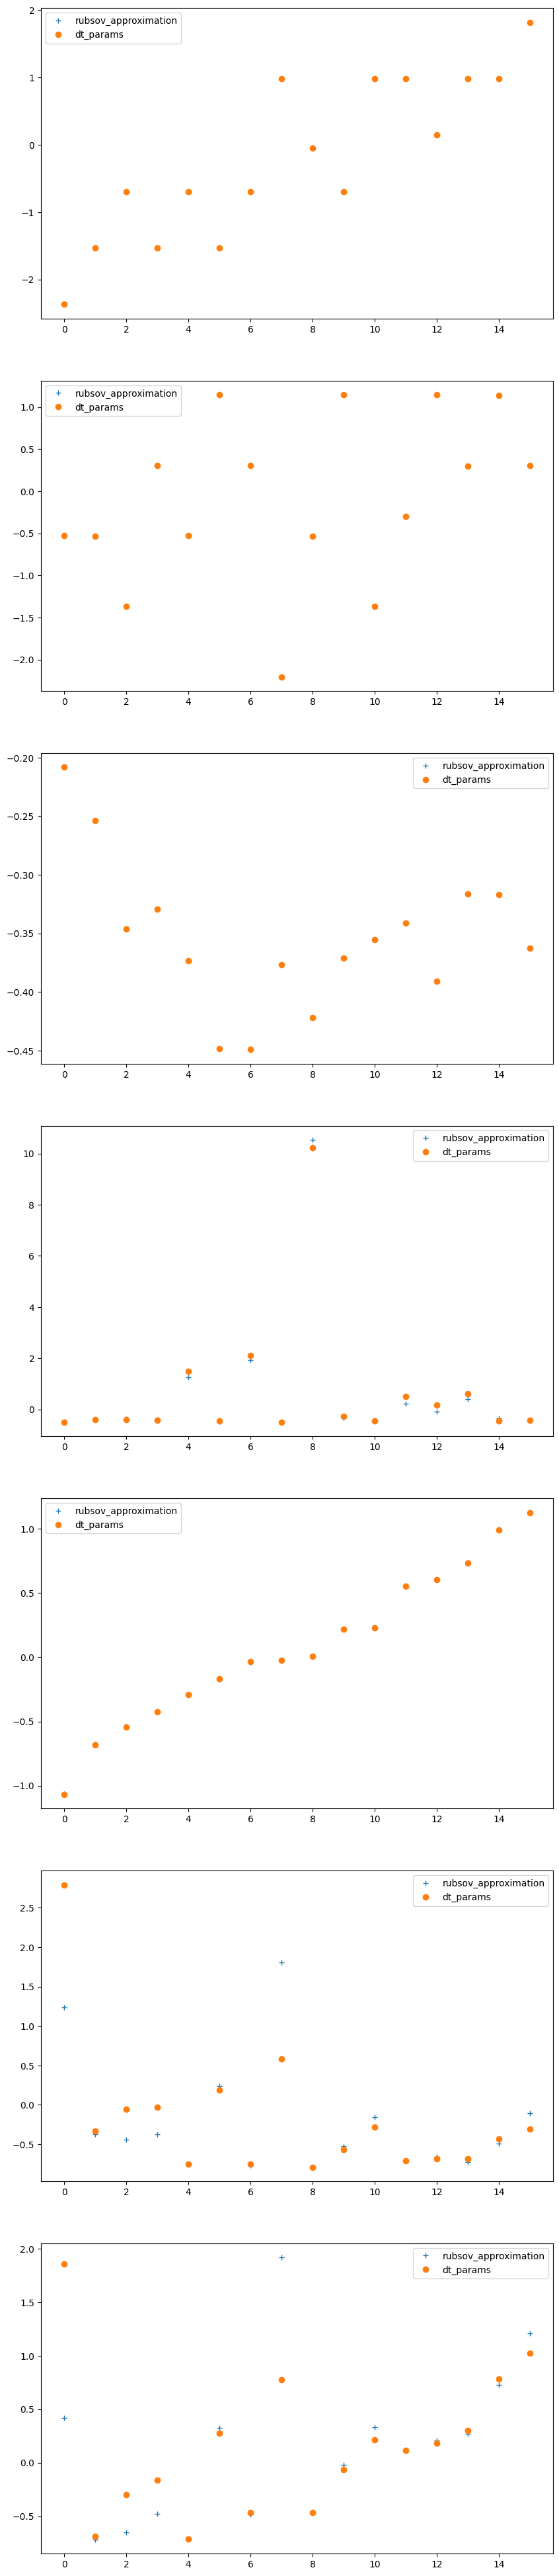

In [5]:
# show dt_params_rubsov_approximation

i = 20
fig, ax = plt.subplots(7,1, figsize=(10, 50))
for j in range(7):
    ax[j].plot(dt_params_rubsov_approximation_pr[i][:,j], '+', label='rubsov_approximation')
    ax[j].plot(dt_params_pr[i][:,j], 'o', label='dt_params')
    ax[j].legend()
plt.show()


In [6]:
# path_save = '/home/rfit/Telescope_Array/phd_work/src/train_VAE/runs_tests_Kharuk_one_work'
# path_save = '/home/rfit/Telescope_Array/phd_work/src/train_VAE/info_Transfoemr_Kharuk_one_work_photon_0.01'
# path_save = '/home/rfit/Telescope_Array/phd_work/src/train_VAE/info_Transfoemr_Kharuk_one_work_photon_0.01_FullyConnected_dim_6'
path_save_1 = '/home/rfit/Telescope_Array/phd_work/src/train_VAE/Original_VAE_dim_5_norm'

path_save_2 = '/home/rfit/Telescope_Array/phd_work/src/train_VAE/info_Transfoemr_Kharuk_one_work_photon_0.01_FullyConnected_Dim_6_recos'

In [7]:
os.listdir(path_save_1)

['photon', 'pr']

In [8]:
os.listdir(os.path.join(path_save_1, 'pr'))

['recos.npy',
 'reconstruction_data.npy',
 'preds_num_det.npy',
 'num_det.npy',
 'recon_loss.npy',
 'original_data.npy',
 'embading.npy',
 'preds_log_var.npy',
 'loss_num_det.npy']

In [ ]:
class AnalysisAnomaly:
    def __init__(self, path_save):
        self.path_save = path_save

    def anomaly_score(self):
        path_save = self.path_save
        reconstruction_data_pr = np.load(os.path.join(path_save, 'pr', 'reconstruction_data.npy'), allow_pickle = True)
        reconstruction_data_photon = np.load(os.path.join(path_save, 'photon', 'reconstruction_data.npy'), allow_pickle = True)

        
        num_det_pr = np.load(os.path.join(path_save, 'pr', 'num_det.npy'))
        num_det_photon = np.load(os.path.join(path_save, 'photon', 'num_det.npy'))

        recon_loss_pr = np.load(os.path.join(path_save, 'pr', 'recon_loss.npy'))
        recon_loss_photon = np.load(os.path.join(path_save, 'photon', 'recon_loss.npy'))
        
        embading_pr = np.load(os.path.join(path_save, 'pr', 'embading.npy'))
        embading_photon = np.load(os.path.join(path_save, 'photon', 'embading.npy'))
        recos_pr = np.load(os.path.join(path_save, 'pr', 'recos.npy'))
        recos_photon = np.load(os.path.join(path_save, 'photon', 'recos.npy'))

        recos_norming_pr = recos_pr * std_recos + mean_recos
        recos_norming_photon = recos_photon * std_recos + mean_recos

        embading_pr.shape, embading_photon.shape, recos_pr.shape
        self.reconstruction_data_pr = reconstruction_data_pr
        self.reconstruction_data_photon = reconstruction_data_photon
        self.num_det_pr = num_det_pr
        self.num_det_photon = num_det_photon
        self.recon_loss_pr = recon_loss_pr
        self.recon_loss_photon = recon_loss_photon
        self.embading_pr = embading_pr
        self.embading_photon = embading_photon
        return reconstruction_data_pr, reconstruction_data_photon, num_det_pr, num_det_photon, recon_loss_pr, recon_loss_photon, embading_pr, embading_photon, recos_pr, recos_photon, recos_norming_pr, recos_norming_photon
    
    def show_reconstruction(self):
        from catboost import CatBoostRegressor
        from sklearn.neural_network import MLPRegressor
        from sklearn.model_selection import train_test_split
        from tqdm.notebook import tqdm

        embading_pr = self.embading_pr
        recos_pr = self.recos_pr
        train_latent_pr, test_latent_pr, train_recos_pr, test_recos_pr = train_test_split(embading_pr, recos_pr, test_size=0.2, random_state=42)

        info = {}
        for i in tqdm(range(recos_pr.shape[1])):
            regressor = CatBoostRegressor(n_estimators=1000, learning_rate=0.01, depth=10, random_seed=42,
                loss_function='RMSE', eval_metric='RMSE', early_stopping_rounds=20)

            regressor.fit(train_latent_pr, train_recos_pr[:,i], eval_set=(test_latent_pr, test_recos_pr[:,i]), use_best_model=True)
            # regressor = MLPRegressor(hidden_layer_sizes=(32,64), max_iter=1000, random_state=42,
            #     early_stopping=True, validation_fraction=0.2, solver='adam')
            # regressor.fit(train_latent_pr, train_recos_pr[:,i])
            score = regressor.score(test_latent_pr, test_recos_pr[:,i])
            info[i] = {'model': regressor, "metric": score}
        feaches_names = """
            0. theta
            1. phi
            2. S_800
            3. E_gamma
            4. d_border, km
            5. chi2/ndof for joint fit
            6. Linsley front curvature
            7. Area-over-peak (AOP) 1200
            8. AOP slope
            9. S_b parameter, b=2.5 (arXiv:1104.3399, arXiv:1305.7439)
            10. S_b parameter, b=4.0
            11. sum of all signals in all detectors
            12. asymmetry  of  the  summed signal  at  the  upper  and  lower layers of detectors
            13. total number of peaks in event
            14. number of peaks for the detector with the largest signal
        """
        feaches_names = feaches_names.split('\n')[1:-1]
        feaches_names = [i.replace(' ', '') for i in feaches_names]
        feaches_names
        fig, ax = plt.subplots(recos_pr.shape[1],1, figsize=(10, recos_pr.shape[1]*10))
        for i in range(recos_pr.shape[1]):
            pred = info[i]['model'].predict(test_latent_pr)
            ax[i].scatter(test_recos_pr[:,i], pred, label=f'{i} feature')
            ax[i].plot([test_recos_pr[:,i].min(), test_recos_pr[:,i].min()], [test_recos_pr[:,i].max(), test_recos_pr[:,i].max()], color='k', linestyle='--', label='true')
            ax[i].legend()
            ax[i].set_title(feaches_names[i])
            ax[i].set_xlabel('true')
            ax[i].set_ylabel('pred')
        plt.show()
    def anomaly_score(self):
        embading_pr = self.embading_pr
        embading_photon = self.embading_photon
        num_det_pr = self.num_det_pr
        num_det_photon = self.num_det_photon
        recon_loss_pr = self.recon_loss_pr
        recon_loss_photon = self.recon_loss_photon

        import numpy as np
        import pandas as pd

        from sklearn.preprocessing import RobustScaler
        from sklearn.neighbors import NearestNeighbors, LocalOutlierFactor
        from sklearn.ensemble import IsolationForest

        num =47000
        num_ph = 400
        print(f'part of data {num_ph/num}')
        test_num = 10000
        print('pr', embading_pr.shape, 'ph', embading_photon.shape)
        index = np.random.randint(0, len(embading_pr), num)
        index_ph = np.random.randint(0, len(embading_photon), num_ph)
        feaches_pr = np.concatenate([embading_pr[index], num_det_pr[index].reshape(-1,1), recon_loss_pr[index].reshape(-1,1), recos_pr[index]], axis=1)

        feaches_photon = np.concatenate([embading_photon[index_ph], num_det_photon[index_ph].reshape(-1,1), recon_loss_photon[index_ph].reshape(-1,1), recos_photon[index_ph]], axis=1)

        feaches = np.concatenate([feaches_pr, feaches_photon], axis=0)
        # label_pr = np.zeros(num)
        # label_ph = np.ones(num_ph)
        # label = np.concatenate((label_pr, label_ph))
        # feaches_pr_test = np.concatenate([embading_pr[-test_num:], num_det_pr[-test_num:].reshape(-1,1), recon_loss_pr[-test_num:].reshape(-1,1)], axis=1)

        # feaches_photon_test = np.concatenate([embading_photon[-test_num:], num_det_photon[-test_num:].reshape(-1,1), recon_loss_photon[-test_num:].reshape(-1,1)], axis=1)
        # feaches: твой массив shape [N, D]
        X = feaches.copy()
        print(X.shape)
        # Лучше RobustScaler, чем StandardScaler, для задач с выбросами
        scaler = RobustScaler()
        X_scaled = scaler.fit_transform(X)

        

        

                    

In [18]:
reconstruction_data_pr = np.load(os.path.join(path_save, 'pr', 'reconstruction_data.npy'), allow_pickle = True)
reconstruction_data_photon = np.load(os.path.join(path_save, 'photon', 'reconstruction_data.npy'), allow_pickle = True)
reconstruction_data_pr.shape, reconstruction_data_photon.shape, reconstruction_data_pr[5].shape


((210315,), (210851,), (10, 5))

In [19]:
print(len(dt_params_pr), len(dt_params_ph), len(dt_params_rubsov_approximation_pr), len(dt_params_rubsov_approximation_ph))


210315 210851 210315 210851


In [16]:
sigal=-100
index_max_signal=0
for i in range(len(dt_params_pr)):
    if dt_params_pr[i][:,3].max() > sigal:
        sigal = dt_params_pr[i][:,3].max()
        index_max_signal = i
print(index_max_signal, sigal)


25912 13.7732315


In [17]:
n=36
index_list=[]
for i in range(len(dt_params_pr)):
    if len(dt_params_pr[i]) ==n:
        print(i)
        index_list.append(i)
print(index_list)


62196
90766
143540
169931
180321
[62196, 90766, 143540, 169931, 180321]


36 36 36
36 36 36


IndexError: index 5 is out of bounds for axis 1 with size 5

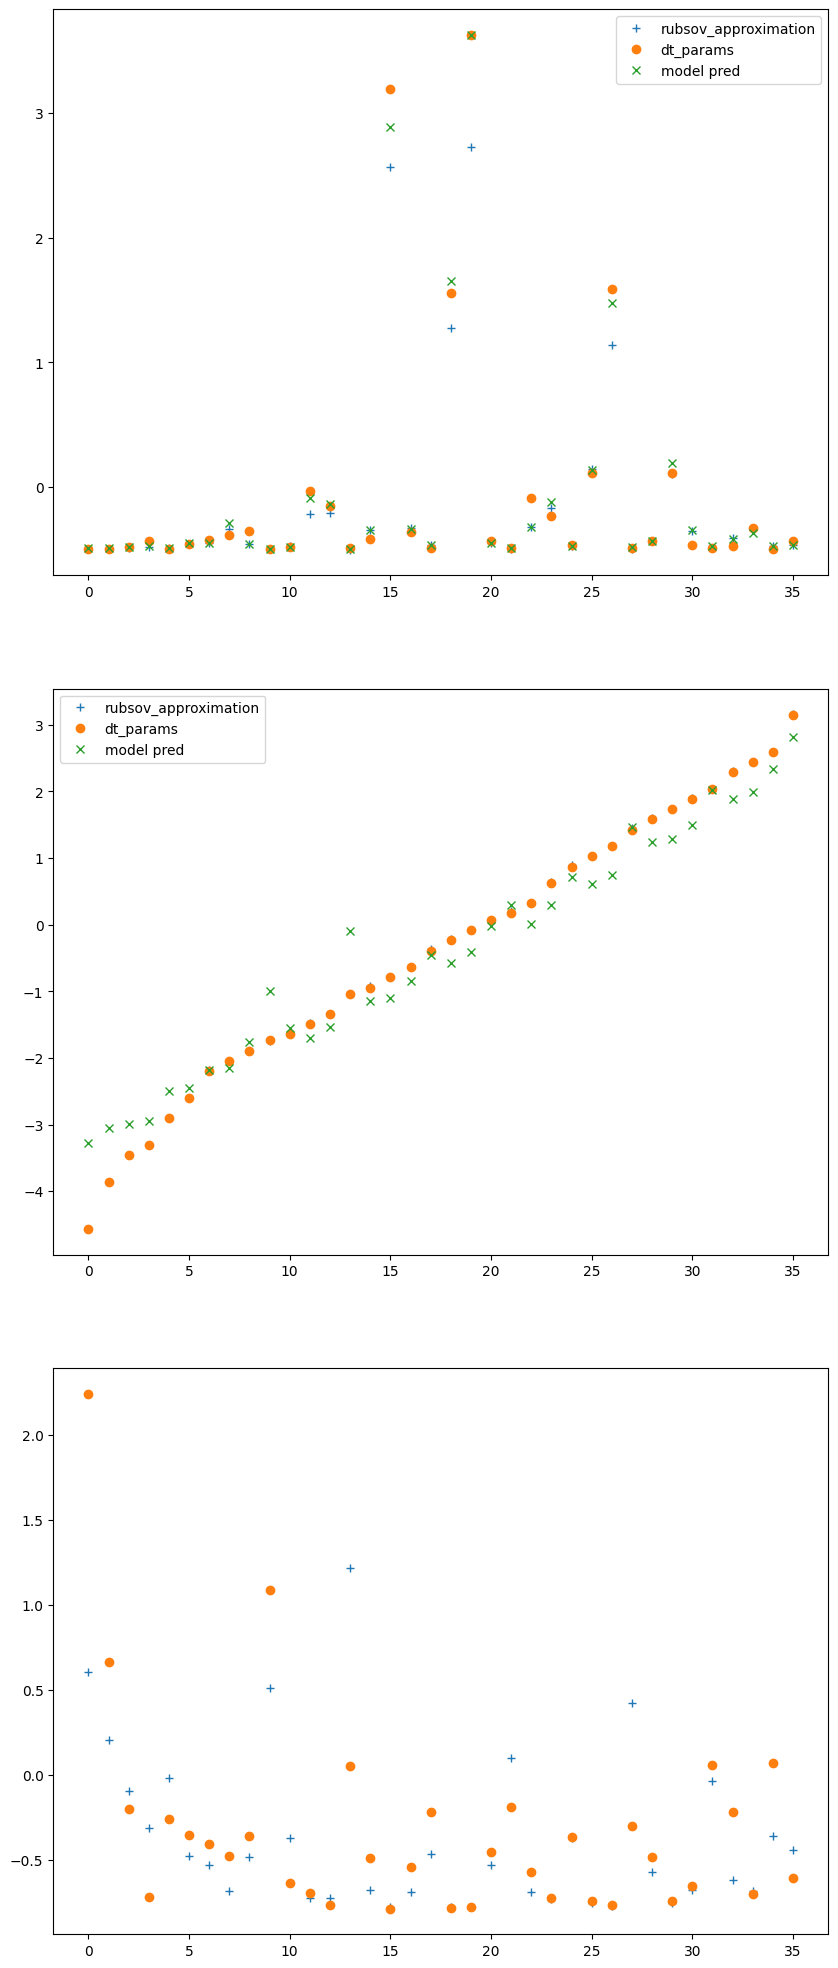

In [ ]:
i = 180321
fig, ax = plt.subplots(3,1, figsize=(10, 25))

for j in range(2):
    if j == 0:

        ax[j].plot(dt_params_rubsov_approximation_pr[i][:,3], '+', label='rubsov_approximation')
        ax[j].plot(dt_params_pr[i][:,3], 'o', label='dt_params')
        ax[j].plot(reconstruction_data_pr[i][:,3], 'x', label='model pred')
        ax[j].legend()
    if j == 1:
        ax[j].plot(dt_params_rubsov_approximation_pr[i][:,6], '+', label='rubsov_approximation')
        ax[j].plot(dt_params_pr[i][:,6], 'o', label='dt_params')
        ax[j].plot(reconstruction_data_pr[i][:,4], 'x', label='model pred')
        ax[j].legend()
    print(len(dt_params_pr[i][:,j+3]), len(dt_params_rubsov_approximation_pr[i][:,j+3]), len(reconstruction_data_pr[i][:,j+3]))
plt.show()

In [6]:
num_det_pr = np.load(os.path.join(path_save, 'pr', 'num_det.npy'))
num_det_photon = np.load(os.path.join(path_save, 'photon', 'num_det.npy'))
num_det_pr.shape, num_det_photon.shape, num_det_pr[:20]

((210315,),
 (210851,),
 array([ 8.,  9., 15.,  9., 13., 10.,  7.,  7.,  9., 11., 12., 19., 10.,
        13., 12.,  7., 12., 12.,  8., 17.]))

In [7]:
recon_loss_pr = np.load(os.path.join(path_save, 'pr', 'recon_loss.npy'))
recon_loss_photon = np.load(os.path.join(path_save, 'photon', 'recon_loss.npy'))
recon_loss_pr.shape, recon_loss_photon.shape, recon_loss_pr[:20]

((210315,),
 (210851,),
 array([0.00090764, 0.00095818, 0.00150479, 0.0007468 , 0.00091271,
        0.00225842, 0.00560359, 0.00341454, 0.00097142, 0.01965975,
        0.00854161, 0.00240543, 0.00226425, 0.0067755 , 0.00608378,
        0.00147277, 0.0012897 , 0.00386556, 0.00149127, 0.00311781]))

In [89]:
def error_recon(x, label):
    # shape x [num_det, chanals]
    return np.sqrt(np.sum((x - label)**2, axis=0))
protons_datasets = [reconstruction_data_pr, dt_params_rubsov_approximation_pr]
photons_datasets = [reconstruction_data_photon, dt_params_rubsov_approximation_ph]

target_datasets_pr = dt_params_pr
target_datasets_ph = dt_params_ph

losses_dict_pr = {}
losses_dict_ph = {}
for j, d in enumerate(protons_datasets):
    losses_dict_pr[j] = {}
    losses_dict_ph[j] = {}
for i in tqdm(range(len(reconstruction_data_pr))):
    for j, d in enumerate(protons_datasets):
        if len(target_datasets_pr[i]) != len(d[i]):
            raise ValueError(f'len(target_datasets_pr[i]) != len(d[i])')
        num_det = len(target_datasets_pr[i])
        error = error_recon(d[i], target_datasets_pr[i])
        if num_det not in losses_dict_pr[j]:
            losses_dict_pr[j][num_det] = []
        losses_dict_pr[j][num_det].append(error)
for i in tqdm(range(len(reconstruction_data_photon))):
    for j, d in enumerate(photons_datasets):
        if len(target_datasets_ph[i]) != len(d[i]):
            raise ValueError(f'len(target_datasets_ph[i]) != len(d[i])')
        num_det = len(target_datasets_ph[i])
        error = error_recon(d[i], target_datasets_ph[i])
        if num_det not in losses_dict_ph[j]:
            losses_dict_ph[j][num_det] = []
        losses_dict_ph[j][num_det].append(error)

  0%|          | 0/210315 [00:00<?, ?it/s]

  0%|          | 0/210851 [00:00<?, ?it/s]

In [90]:
mean_losses_pr = {}
mean_losses_ph = {}
std_losses_pr = {}
std_losses_ph = {}

for d, errors_dict in losses_dict_pr.items():
    mean_losses_pr[d] = {}
    std_losses_pr[d] = {}
    for num_det, errors in errors_dict.items():
        errors = np.array(errors)
        mean_losses_pr[d][num_det] = errors.mean(axis=0)
        std_losses_pr[d][num_det] = errors.std(axis=0)

for d, errors_dict in losses_dict_ph.items():
    mean_losses_ph[d] = {}
    std_losses_ph[d] = {}
    for num_det, errors in errors_dict.items():
        errors = np.array(errors)
        mean_losses_ph[d][num_det] = errors.mean(axis=0)
        std_losses_ph[d][num_det] = errors.std(axis=0)


In [91]:
mean_losses_pr

{0: {8: array([2.365129  , 2.4316728 , 2.3909109 , 0.13766296, 0.04378413,
         0.22390254], dtype=float32),
  9: array([2.6499767 , 2.728023  , 2.551231  , 0.16130984, 0.04756224,
         0.27471247], dtype=float32),
  15: array([4.348067  , 4.456026  , 3.2877831 , 0.3007212 , 0.08105101,
         0.57555073], dtype=float32),
  13: array([3.7801805 , 3.8752708 , 3.0774672 , 0.25762302, 0.06751539,
         0.49042186], dtype=float32),
  10: array([2.9290402 , 3.024005  , 2.712504  , 0.18501873, 0.05204   ,
         0.3305635 ], dtype=float32),
  7: array([2.0722616 , 2.144269  , 2.2043014 , 0.11805878, 0.04171303,
         0.17686202], dtype=float32),
  11: array([3.211807  , 3.309255  , 2.8404105 , 0.20918429, 0.057035  ,
         0.38417378], dtype=float32),
  12: array([3.49899   , 3.5846446 , 2.9871447 , 0.235869  , 0.06261972,
         0.43695936], dtype=float32),
  19: array([5.525165  , 5.629018  , 3.5569015 , 0.36605275, 0.10229485,
         0.6889662 ], dtype=float32),
 

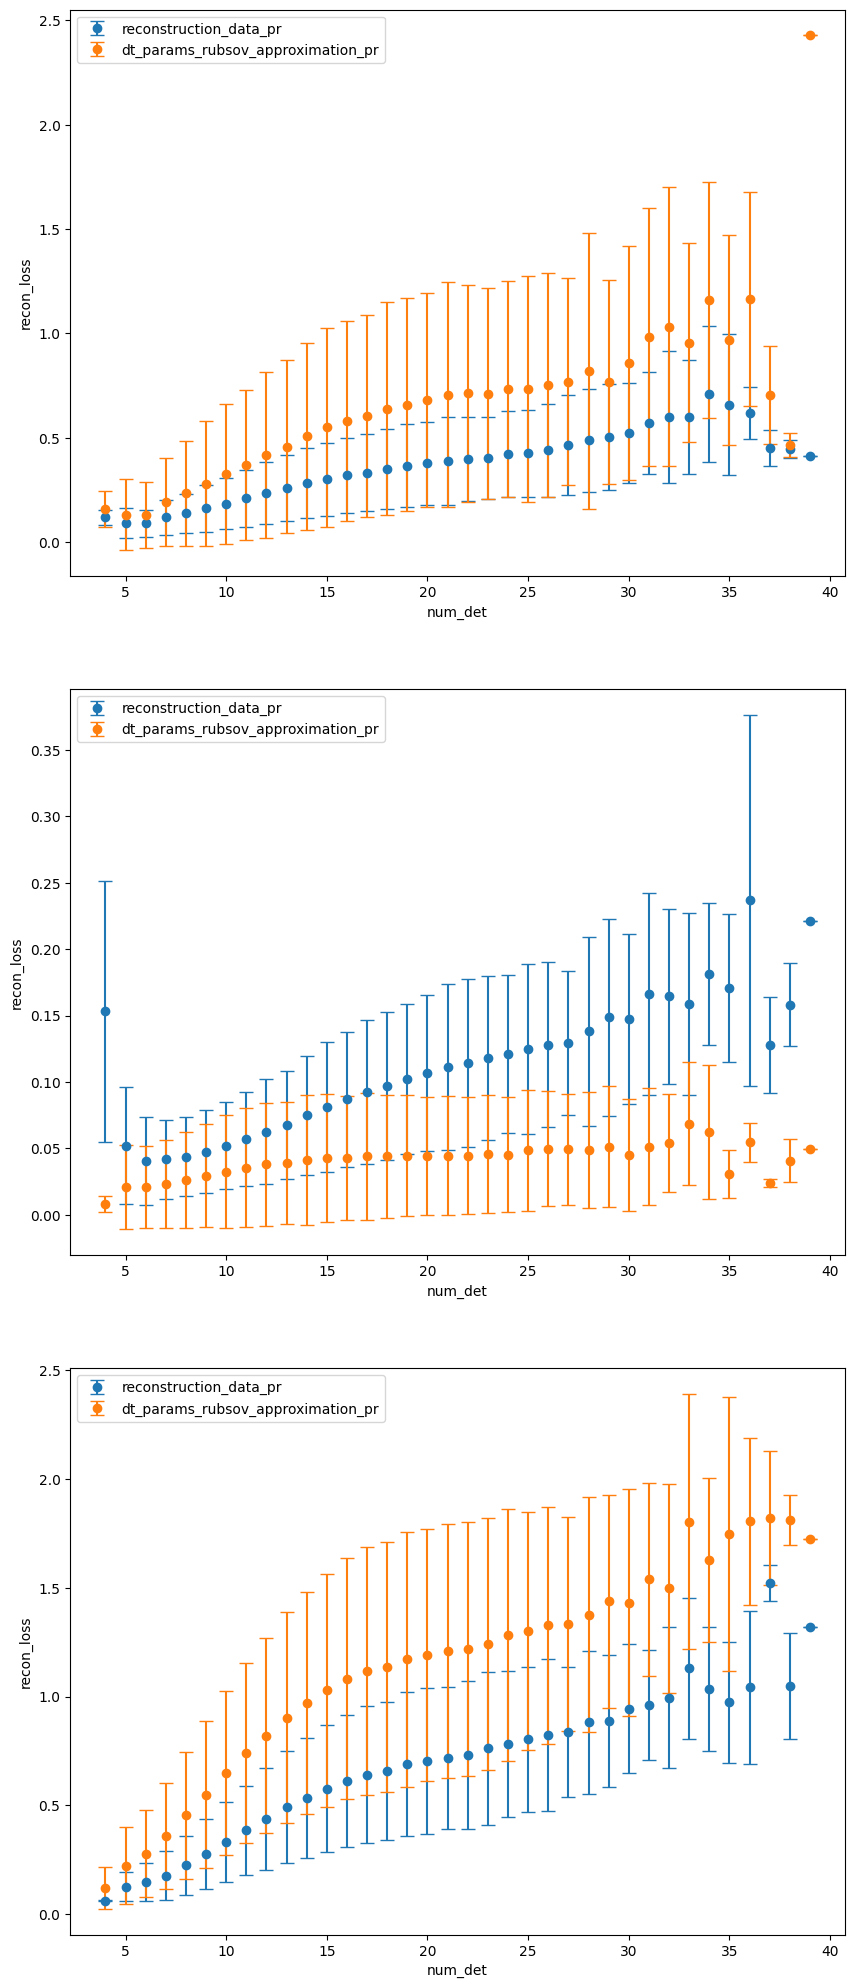

In [92]:
fig, ax = plt.subplots(3,1, figsize=(10, 25))
y_lim = [3,0.4,3]
names_datasets = ['reconstruction_data_pr', 'dt_params_rubsov_approximation_pr']
for d in mean_losses_pr.keys():
    # mean_losses_pr[j] - словарь с коль-вом сработавших детекторов и ошибкой поканальной
    num_det_list = list(mean_losses_pr[d].keys())
    mean_lists = np.array(list(mean_losses_pr[d].values()))
    std_lists = np.array(list(std_losses_pr[d].values()))
    for i in range(3):
        # ax[i].plot(num_det_list, mean_lists[:,i+3], label=f'{d} pr')
        # ax[i].plot(num_det_list, mean_lists[:,i+3] + std_lists[:,i+3], label=f'{d} pr+ std')
        # ax[i].plot(num_det_list, mean_lists[:,i+3] - std_lists[:,i+3], label=f'{d} pr-std')
        ax[i].errorbar(num_det_list, mean_lists[:,i+3], yerr=std_lists[:,i+3],
                       marker='o', linestyle='none',capsize = 5, label=names_datasets[d])
        ax[i].legend()
        ax[i].set_xlabel('num_det')
        ax[i].set_ylabel('recon_loss')
        # ax[i].set_ylim(0, y_lim[i])
plt.show()


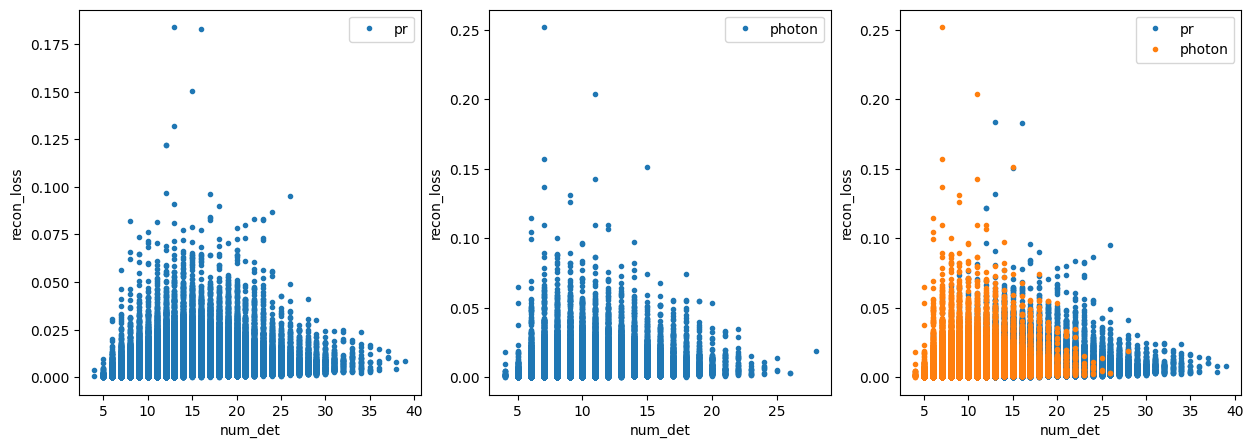

In [8]:
fig, ax = plt.subplots(1,3, figsize=(15, 5))
ax[0].plot(num_det_pr, recon_loss_pr, '.', label='pr')
ax[0].legend()
ax[1].plot(num_det_photon, recon_loss_photon, '.', label='photon')
ax[1].legend()
ax[2].plot(num_det_pr, recon_loss_pr, '.', label='pr')
ax[2].plot(num_det_photon, recon_loss_photon, '.', label='photon')
ax[2].legend()
for i in range(3):
    ax[i].set_xlabel('num_det')
    ax[i].set_ylabel('recon_loss')
plt.show()

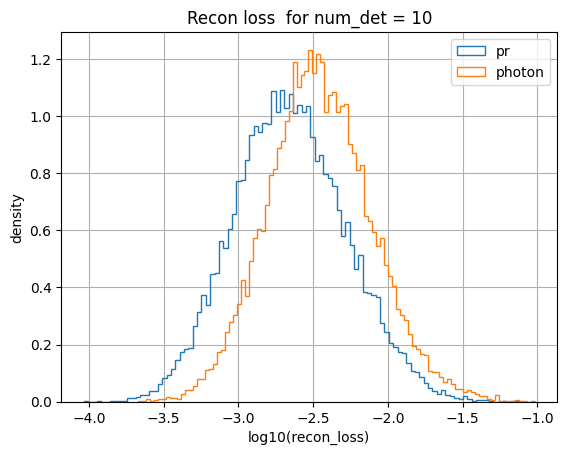

In [9]:
num=10
range_hist = None
plt.hist(np.log10(recon_loss_pr[num_det_pr == num]), density=True, bins=100, label='pr', histtype='step', range=range_hist)
plt.hist(np.log10(recon_loss_photon[num_det_photon == num]), density=True, bins=100, label='photon', histtype='step', range=range_hist)
plt.legend()
plt.title(f'Recon loss  for num_det = {num}')
plt.xlabel('log10(recon_loss)')
plt.ylabel('density')
plt.grid()
plt.show()

In [ ]:
embading_pr_1 = np.load(os.path.join(path_save, 'pr', 'embading.npy'))
embading_photon_1 = np.load(os.path.join(path_save, 'photon', 'embading.npy'))
recos_pr_1 = np.load(os.path.join(path_save, 'pr', 'recos.npy'))
recos_photon_1 = np.load(os.path.join(path_save, 'photon', 'recos.npy'))

recos_norming_pr = recos_pr * std_recos + mean_recos
recos_norming_photon = recos_photon * std_recos + mean_recos

embading_pr.shape, embading_photon.shape, recos_pr.shape,




((210315, 6), (210851, 6), (210315, 15))


    recos (num_evs,15):
    0. theta
    1. phi
    2. S_800
    3. E_gamma
    4. d_border, km
    5. chi2/ndof for joint fit
    6. Linsley front curvature
    7. Area-over-peak (AOP) 1200
    8. AOP slope
    9. S_b parameter, b=2.5 (arXiv:1104.3399, arXiv:1305.7439)
    10. S_b parameter, b=4.0
    11. sum of all signals in all detectors
    12. asymmetry  of  the  summed signal  at  the  upper  and  lower layers of detectors
    13. total number of peaks in event
    14. number of peaks for the detector with the largest signal

In [17]:
# проверка физической информативности латентного пространства
from catboost import CatBoostRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.model_selection import train_test_split
from tqdm.notebook import tqdm
train_latent_pr, test_latent_pr, train_recos_pr, test_recos_pr = train_test_split(embading_pr, recos_pr, test_size=0.2, random_state=42)

info = {}
for i in tqdm(range(recos_pr.shape[1])):
    regressor = CatBoostRegressor(n_estimators=1000, learning_rate=0.01, depth=10, random_seed=42,
        loss_function='RMSE', eval_metric='RMSE', early_stopping_rounds=20)

    regressor.fit(train_latent_pr, train_recos_pr[:,i], eval_set=(test_latent_pr, test_recos_pr[:,i]), use_best_model=True)
    # regressor = MLPRegressor(hidden_layer_sizes=(32,64), max_iter=1000, random_state=42,
    #     early_stopping=True, validation_fraction=0.2, solver='adam')
    # regressor.fit(train_latent_pr, train_recos_pr[:,i])
    score = regressor.score(test_latent_pr, test_recos_pr[:,i])
    info[i] = {'model': regressor, "metric": score}
    


  0%|          | 0/15 [00:00<?, ?it/s]

0:	learn: 1.0532797	test: 1.0508098	best: 1.0508098 (0)	total: 84.1ms	remaining: 1m 23s
1:	learn: 1.0473665	test: 1.0448863	best: 1.0448863 (1)	total: 102ms	remaining: 50.9s
2:	learn: 1.0416675	test: 1.0392138	best: 1.0392138 (2)	total: 121ms	remaining: 40.1s
3:	learn: 1.0358287	test: 1.0333799	best: 1.0333799 (3)	total: 138ms	remaining: 34.5s
4:	learn: 1.0300611	test: 1.0275975	best: 1.0275975 (4)	total: 155ms	remaining: 30.8s
5:	learn: 1.0243550	test: 1.0219057	best: 1.0219057 (5)	total: 173ms	remaining: 28.6s
6:	learn: 1.0187206	test: 1.0162759	best: 1.0162759 (6)	total: 191ms	remaining: 27.1s
7:	learn: 1.0132121	test: 1.0107682	best: 1.0107682 (7)	total: 208ms	remaining: 25.8s
8:	learn: 1.0077287	test: 1.0052833	best: 1.0052833 (8)	total: 225ms	remaining: 24.8s
9:	learn: 1.0023429	test: 0.9998968	best: 0.9998968 (9)	total: 243ms	remaining: 24.1s
10:	learn: 0.9970259	test: 0.9945927	best: 0.9945927 (10)	total: 260ms	remaining: 23.4s
11:	learn: 0.9917670	test: 0.9893477	best: 0.98934

In [23]:

feaches_names = """
    0. theta
    1. phi
    2. S_800
    3. E_gamma
    4. d_border, km
    5. chi2/ndof for joint fit
    6. Linsley front curvature
    7. Area-over-peak (AOP) 1200
    8. AOP slope
    9. S_b parameter, b=2.5 (arXiv:1104.3399, arXiv:1305.7439)
    10. S_b parameter, b=4.0
    11. sum of all signals in all detectors
    12. asymmetry  of  the  summed signal  at  the  upper  and  lower layers of detectors
    13. total number of peaks in event
    14. number of peaks for the detector with the largest signal
"""
feaches_names = feaches_names.split('\n')[1:-1]
feaches_names = [i.replace(' ', '') for i in feaches_names]
feaches_names

['0.theta',
 '1.phi',
 '2.S_800',
 '3.E_gamma',
 '4.d_border,km',
 '5.chi2/ndofforjointfit',
 '6.Linsleyfrontcurvature',
 '7.Area-over-peak(AOP)1200',
 '8.AOPslope',
 '9.S_bparameter,b=2.5(arXiv:1104.3399,arXiv:1305.7439)',
 '10.S_bparameter,b=4.0',
 '11.sumofallsignalsinalldetectors',
 '12.asymmetryofthesummedsignalattheupperandlowerlayersofdetectors',
 '13.totalnumberofpeaksinevent',
 '14.numberofpeaksforthedetectorwiththelargestsignal']



In [ ]:

feaches_names = """
    0. theta
    1. phi
    2. S_800
    3. E_gamma
    4. d_border, km
    5. chi2/ndof for joint fit
    6. Linsley front curvature
    7. Area-over-peak (AOP) 1200
    8. AOP slope
    9. S_b parameter, b=2.5 (arXiv:1104.3399, arXiv:1305.7439)
    10. S_b parameter, b=4.0
    11. sum of all signals in all detectors
    12. asymmetry  of  the  summed signal  at  the  upper  and  lower layers of detectors
    13. total number of peaks in event
    14. number of peaks for the detector with the largest signal
"""
feaches_names = feaches_names.split('\n')[1:-1]
feaches_names = [i.replace(' ', '') for i in feaches_names]
feaches_names
fig, ax = plt.subplots(recos_pr.shape[1],1, figsize=(10, recos_pr.shape[1]*10))
for i in range(recos_pr.shape[1]):
    pred = info[i]['model'].predict(test_latent_pr)
    ax[i].scatter(test_recos_pr[:,i], pred, label=f'{i} feature')
    ax[i].plot([test_recos_pr[:,i].min(), test_recos_pr[:,i].min()], [test_recos_pr[:,i].max(), test_recos_pr[:,i].max()], color='k', linestyle='--', label='true')
    ax[i].legend()
    ax[i].set_title(feaches_names[i])
    ax[i].set_xlabel('true')
    ax[i].set_ylabel('pred')
plt.show()

In [25]:
# В изначально ненормированных данных val*10^18

# После нормировки 
# 0- это 0
# 1.0 энергия 10^18
# 10.0 энергия 10^19

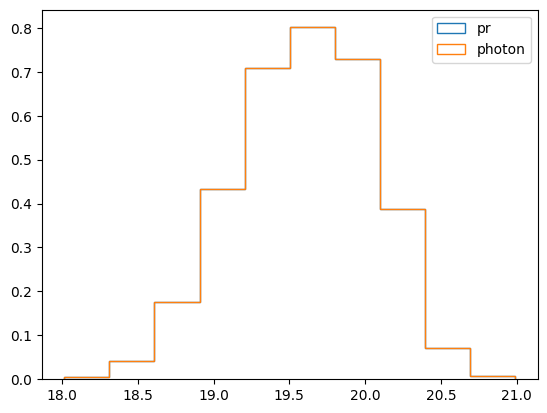

In [27]:
Energy_pr = np.log10(recos_norming_pr[:,3])+18
Energy_photon = np.log10(recos_norming_photon[:,3])+18
plt.hist(Energy_pr,histtype='step',density=True, label='pr')
plt.hist(Energy_photon,histtype='step',density=True, label='photon')
plt.legend()


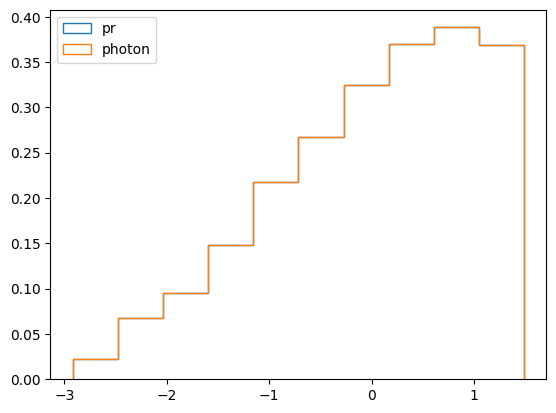

In [28]:
plt.hist(recos_pr[:,0],histtype='step',density=True, label='pr')
plt.hist(recos_photon[:,0],histtype='step',density=True, label='photon')
plt.legend()

In [30]:
def get_metrics(score_samples, score_samples_photon, th):
    FP_index = np.where(score_samples < th)[0]
    TP_index = np.where(score_samples_photon < th)[0]
    FN_index = np.where(score_samples_photon > th)[0]
    TN_index = np.where(score_samples > th)[0]
    part_anomalys_pr = len(FP_index)/len(score_samples)
    part_anomalys_ph = len(TP_index)/len(score_samples_photon)
    recall = len(TP_index) / (len(TP_index) + len(FN_index)+1e-10)
    precision = len(TP_index) / (len(TP_index) + len(FP_index)+1e-10)
    f1 = 2 * precision * recall / (precision + recall+1e-10)
    return recall, precision, f1, part_anomalys_pr, part_anomalys_ph

In [31]:
from sklearn.metrics import roc_curve, auc
from sklearn.neighbors import KernelDensity
def full_test_prob(feaches_pr, feaches_photon,feaches_pr_test = None,n_components=1, range_hist=(-20, 0)):
    fig, axs = plt.subplots(3, 1, figsize=(7, 15))
    # clf = mixture.GaussianMixture(n_components=n_components, covariance_type="full")
    clf = KernelDensity(kernel='gaussian', bandwidth=0.1)
    clf.fit(feaches_pr)
    if feaches_pr_test is None:
        score_samples = clf.score_samples(feaches_pr)
        score_samples_photon = clf.score_samples(feaches_photon)
    else:
        score_samples = clf.score_samples(feaches_pr_test)
        score_samples_photon = clf.score_samples(feaches_photon)
    print(score_samples)
    print(score_samples_photon)
    axs[0].hist(score_samples, bins=100, label='pr', histtype='step', density=True, range=range_hist)
    axs[0].hist(score_samples_photon, bins=100, label='ph', histtype='step', density=True, range=range_hist)
    axs[0].legend()
    axs[0].set_title('hist')
    axs[0].grid()

    recall_list = []    
    precision_list = []
    f1_list = []
    part_anomalys_pr_list = []
    part_anomalys_ph_list = []
    min_score = min(score_samples.min(), score_samples_photon.min())
    max_score = max(score_samples.max(), score_samples_photon.max())
    for th in np.linspace(min_score, max_score, 100):
        recall, precision, f1, part_anomalys_pr, part_anomalys_ph = get_metrics(score_samples, score_samples_photon, th)
        recall_list.append(recall)
        precision_list.append(precision)
        f1_list.append(f1)
        part_anomalys_pr_list.append(part_anomalys_pr)
        part_anomalys_ph_list.append(part_anomalys_ph)
    axs[1].plot(np.linspace(-20, 2, 100), recall_list, label='recall')
    axs[1].plot(np.linspace(-20, 2, 100), precision_list, label='precision')
    axs[1].plot(np.linspace(-20, 2, 100), f1_list, label='f1')
    axs[1].plot(np.linspace(-20, 2, 100), part_anomalys_pr_list, label='part_anomalys_pr')
    axs[1].plot(np.linspace(-20, 2, 100), part_anomalys_ph_list, label='part_anomalys_ph')
    axs[1].legend()
    axs[1].set_title('metrics')
    axs[1].grid()

    #roc curve
    label_pr = np.zeros_like(score_samples)
    label_ph = np.ones_like(score_samples_photon)
    label = np.concatenate((label_pr, label_ph))
    loss = np.concatenate((-score_samples, -score_samples_photon))
    fpr, tpr, thresholds = roc_curve(label, loss)
    auc_ = auc(fpr, tpr)
    axs[2].plot(fpr, tpr)
    axs[2].text(0.5, 0.5, f'auc: {auc_:.2f}', fontsize=12, ha='center', va='center')
    axs[2].set_title(f'roc curve')
    axs[2].grid()
    print(thresholds.min(), thresholds.max())
    plt.show()

    
    

In [32]:
import numpy as np
import pandas as pd

from sklearn.preprocessing import RobustScaler
from sklearn.neighbors import NearestNeighbors, LocalOutlierFactor
from sklearn.ensemble import IsolationForest

num =47000
num_ph = 400
print(f'part of data {num_ph/num}')
test_num = 10000
print('pr', embading_pr.shape, 'ph', embading_photon.shape)
index = np.random.randint(0, len(embading_pr), num)
index_ph = np.random.randint(0, len(embading_photon), num_ph)
feaches_pr = np.concatenate([embading_pr[index], num_det_pr[index].reshape(-1,1), recon_loss_pr[index].reshape(-1,1), recos_pr[index]], axis=1)

feaches_photon = np.concatenate([embading_photon[index_ph], num_det_photon[index_ph].reshape(-1,1), recon_loss_photon[index_ph].reshape(-1,1), recos_photon[index_ph]], axis=1)

feaches = np.concatenate([feaches_pr, feaches_photon], axis=0)
# label_pr = np.zeros(num)
# label_ph = np.ones(num_ph)
# label = np.concatenate((label_pr, label_ph))
# feaches_pr_test = np.concatenate([embading_pr[-test_num:], num_det_pr[-test_num:].reshape(-1,1), recon_loss_pr[-test_num:].reshape(-1,1)], axis=1)

# feaches_photon_test = np.concatenate([embading_photon[-test_num:], num_det_photon[-test_num:].reshape(-1,1), recon_loss_photon[-test_num:].reshape(-1,1)], axis=1)
# feaches: твой массив shape [N, D]
X = feaches.copy()
print(X.shape)
# Лучше RobustScaler, чем StandardScaler, для задач с выбросами
scaler = RobustScaler()
X_scaled = scaler.fit_transform(X)

part of data 0.00851063829787234
pr (210315, 6) ph (210851, 6)
(47400, 23)


In [ ]:
# embading, num_det, recon_loss, recos
print(feaches.shape)

(47400, 23)


In [33]:
def show_2d(pr, ph, use_ph=True):
    # pr_index= np.random.randint(0, pr.shape[0], size=5000)
    # ph_index= np.random.randint(0, ph.shape[0], size=5000)
    # pr = pr[pr_index]
    # ph = ph[ph_index]
    reducer = umap.UMAP(n_components=2)
    if use_ph:
        manifold = reducer.fit(np.concatenate([pr, ph], axis=0))
    else:
        manifold = reducer.fit(pr)
    X_pr = manifold.transform(pr)
    X_ph = manifold.transform(ph)


    fig, ax = plt.subplots(2,3, figsize=(12, 12))
    ax_1, ax_2, ax_3 = ax[0]
    ax_1.scatter(X_pr[:, 0], X_pr[:, 1], s=0.5, alpha=0.3, label='pr')
    ax_2.scatter(X_ph[:, 0], X_ph[:, 1], s=0.5, alpha=0.3, label='ph')
    ax_3.scatter(X_pr[:, 0], X_pr[:, 1], s=0.5, alpha=0.3, label='pr')
    ax_3.scatter(X_ph[:, 0], X_ph[:, 1], s=0.5, alpha=0.3, label='ph')
    ax_1.legend()
    ax_2.legend()
    ax_3.legend()

    # tsne = sklearn.manifold.TSNE(n_components=2)
    # if use_ph:
    #     X_tsne = tsne.fit_transform(np.concatenate([pr, ph], axis=0))
    #     X_tsne_pr = X_tsne[:pr.shape[0]]
    #     X_tsne_ph = X_tsne[pr.shape[0]:]
    # else:
    #     X_tsne = tsne.fit_transform(pr)
    #     X_tsne_pr = X_tsne

    # ax_1, ax_2, ax_3 = ax[1]
    # ax_1.scatter(X_tsne_pr[:, 0], X_tsne_pr[:, 1], s=0.5, alpha=0.3, label='pr')
    # ax_2.scatter(X_tsne_ph[:, 0], X_tsne_ph[:, 1], s=0.5, alpha=0.3, label='ph')
    # ax_3.scatter(X_tsne_pr[:, 0], X_tsne_pr[:, 1], s=0.5, alpha=0.3, label='pr')
    # ax_3.scatter(X_tsne_ph[:, 0], X_tsne_ph[:, 1], s=0.5, alpha=0.3, label='ph')
    # ax_1.legend()
    # ax_2.legend()
    # ax_3.legend()
    plt.show()

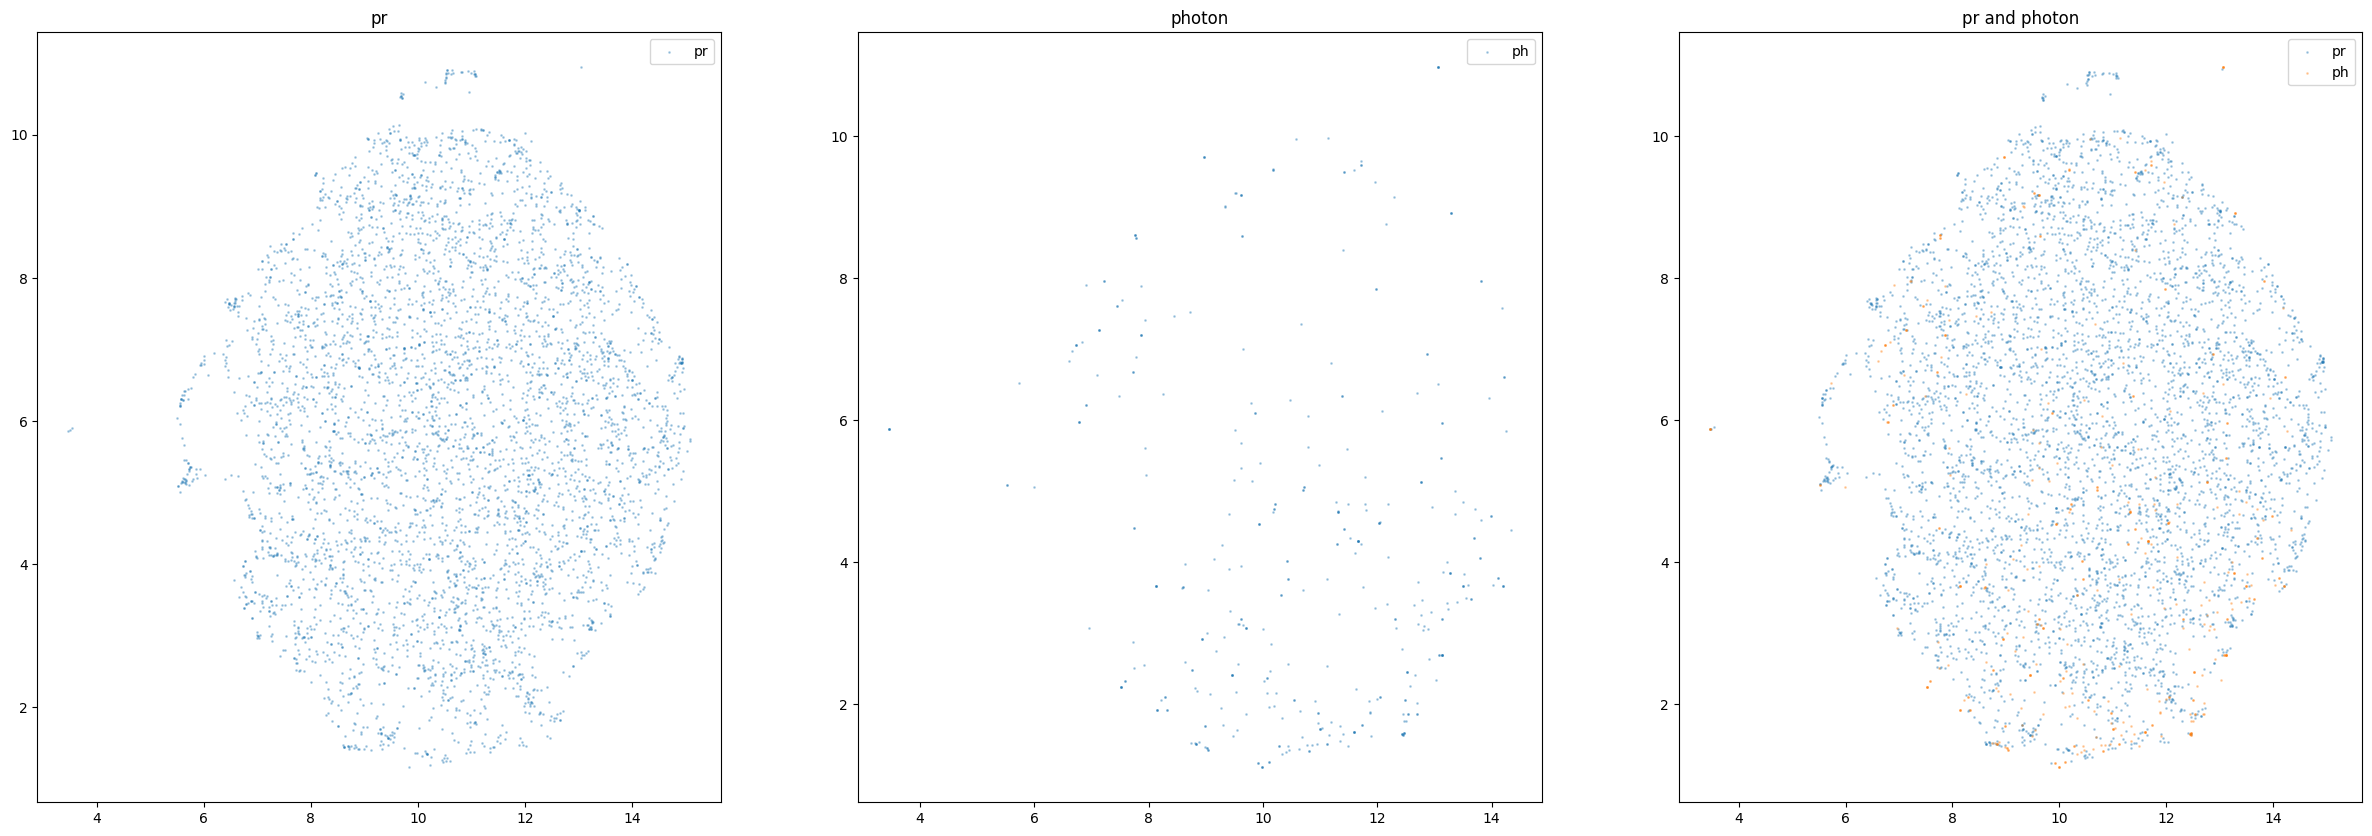

In [36]:
pr = feaches_pr[np.random.randint(0, feaches_pr.shape[0], size=5000)][:,:6]
ph = feaches_photon[np.random.randint(0, feaches_photon.shape[0], size=400)][:,:6]
use_ph = True
fig, ax = plt.subplots(1,3, figsize=(30, 10))

reducer = umap.UMAP(n_components=2)
if use_ph:
    manifold = reducer.fit(np.concatenate([pr, ph], axis=0))
else:
    manifold = reducer.fit(pr)
X_pr = manifold.transform(pr)
X_ph = manifold.transform(ph)

ax_1, ax_2, ax_3 = ax
ax_1.scatter(X_pr[:, 0], X_pr[:, 1], s=1, alpha=0.3, label='pr')
ax_2.scatter(X_ph[:, 0], X_ph[:, 1], s=1, alpha=0.3, label='ph')
ax_3.scatter(X_pr[:, 0], X_pr[:, 1], s=1, alpha=0.3, label='pr')
ax_3.scatter(X_ph[:, 0], X_ph[:, 1], s=1, alpha=0.3, label='ph')
ax_1.set_title('pr')
ax_2.set_title('photon')
ax_3.set_title('pr and photon')
ax_1.legend()
ax_2.legend()
ax_3.legend()


In [37]:
from scipy.stats import gaussian_kde
def show_2d_density(pr, ph, use_ph=True, n_ph=1, density_ph = None, density_pr = None):
    # pr_index= np.random.randint(0, pr.shape[0], size=5000)
    # ph_index= np.random.randint(0, ph.shape[0], size=5000)
    # pr = pr[pr_index]
    # ph = ph[ph_index]
    reducer = umap.UMAP(n_components=2)
    if use_ph:
        manifold = reducer.fit(np.concatenate([pr, ph[::n_ph]], axis=0))
    else:
        manifold = reducer.fit(pr)
    X_pr = manifold.transform(pr)
    X_ph = manifold.transform(ph)

    fig, ax = plt.subplots(2,3, figsize=(12, 12))
    ax_1, ax_2, ax_3 = ax[0]
    ax_1.scatter(X_pr[:, 0], X_pr[:, 1], s=0.5, alpha=0.3, label='pr')
    ax_2.scatter(X_ph[:, 0], X_ph[:, 1], s=0.5, alpha=0.3, label='ph')
    ax_3.scatter(X_pr[:, 0], X_pr[:, 1], s=0.5, alpha=0.3, label='pr')
    ax_3.scatter(X_ph[:, 0], X_ph[:, 1], s=0.5, alpha=0.3, label='ph')
    ax_1.legend()
    ax_2.legend()
    ax_3.legend()

    X_all = np.vstack([X_pr, X_ph[::n_ph]])
    kde = gaussian_kde(X_all.T, )
    density = kde(X_all.T)  # shape: (N,)


    x_min, x_max = X_all[:, 0].min() - 1, X_all[:, 0].max() + 1
    y_min, y_max = X_all[:, 1].min() - 1, X_all[:, 1].max() + 1
    grid_x, grid_y = np.mgrid[x_min:x_max:100j, y_min:y_max:100j]
    density = kde(np.vstack([grid_x.ravel(), grid_y.ravel()]))
    density = density.reshape(grid_x.shape)

    ax_1, ax_2, ax_3 = ax[1]
    # Отображение плотности
    cmap = plt.colormaps['PiYG']
    # (1,0) - плотность для всех точек
    im = ax[1, 0].pcolormesh(grid_x, grid_y, density, cmap=cmap)
    ax[1, 0].set_title('Density (all)')
    fig.colorbar(im, ax=ax[1, 0], label='Density')
    
    ax[1,0].scatter(X_ph[:, 0], X_ph[:, 1],s=1, label='ph')
    # (1,1) и (1,2) можно оставить пустыми или повторить для pr и ph отдельно
    if density_ph is None:
        density_ph = kde(X_ph.T)
    if density_pr is None:
        density_pr = kde(X_pr.T)
    
    im = ax[1, 2].scatter(X_ph[:, 0], X_ph[:, 1], s=1, label='ph', c=density_ph, cmap='viridis')
    ax[1, 2].set_title('Density (ph)')
    fig.colorbar(im, ax=ax[1, 2], label='Density')
    
    ax[1,1].hist(density_ph, bins=100, label='ph', histtype='step', density=True, log=True)
    ax[1,1].hist(density_pr, bins=100, label='pr', histtype='step', density=True, log=True)
    ax[1,1].legend()
    ax[1,1].set_title('Density (ph and pr)')
    ax[1,1].grid()

    plt.tight_layout()
    plt.show()

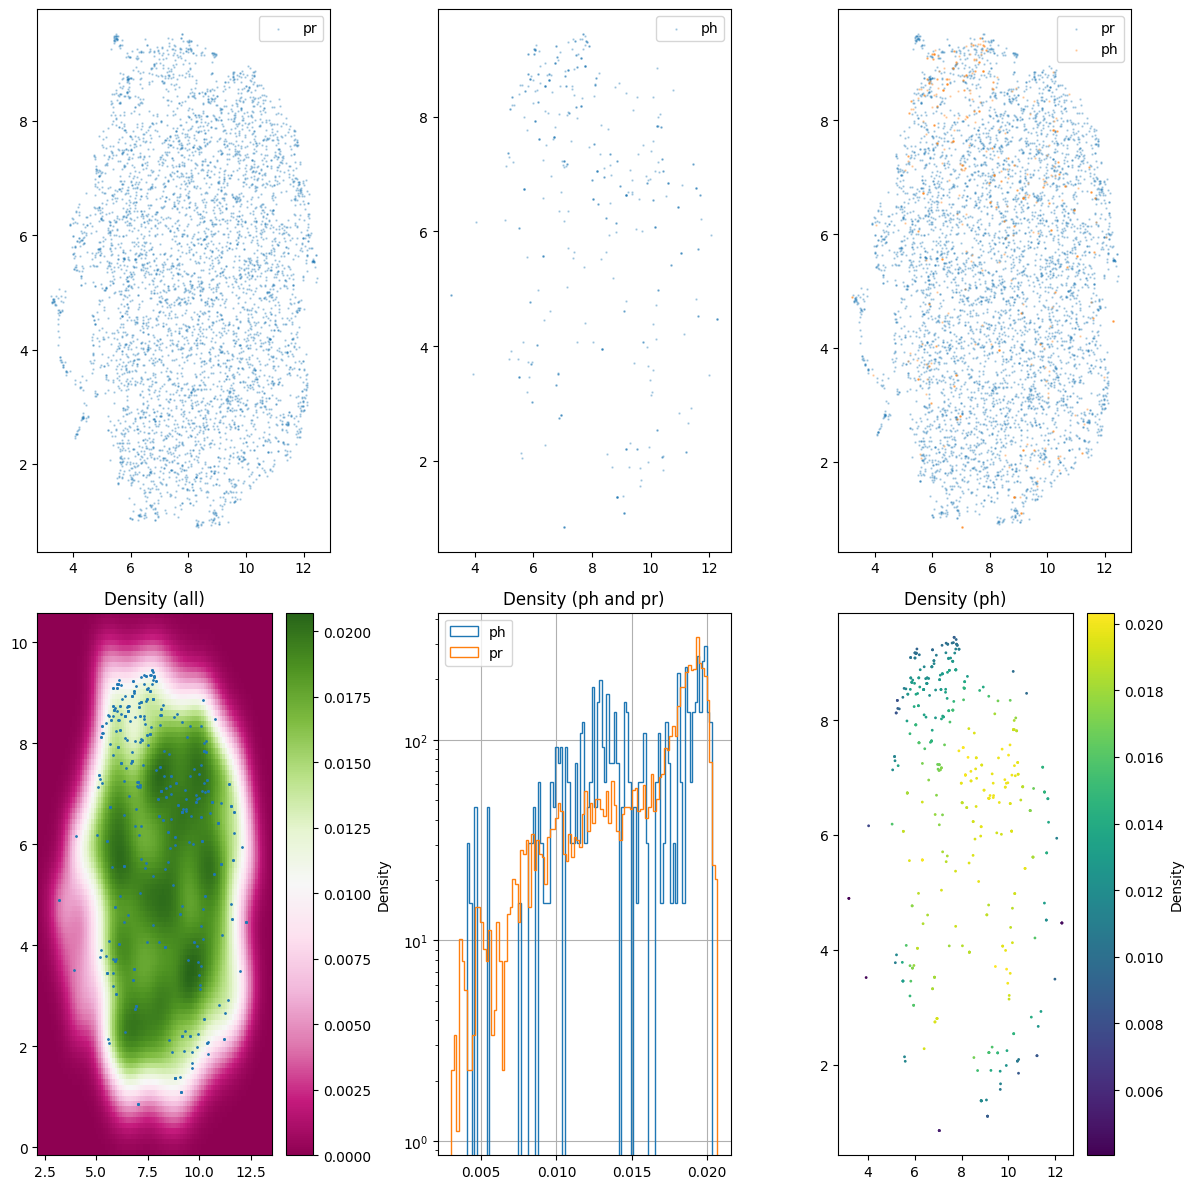

In [38]:
show_2d_density(pr[:10000],ph[:1000], n_ph=10)

In [39]:
def get_metrics(score_samples, score_samples_photon, th):
    FP_index = np.where(score_samples > th)[0]
    TP_index = np.where(score_samples_photon > th)[0]
    FN_index = np.where(score_samples_photon > th)[0]
    TN_index = np.where(score_samples < th)[0]
    part_anomalys_pr = len(FP_index)/len(score_samples)
    part_anomalys_ph = len(TP_index)/len(score_samples_photon)
    recall = len(TP_index) / (len(TP_index) + len(FN_index)+1e-10)
    precision = len(TP_index) / (len(TP_index) + len(FP_index)+1e-10)
    f1 = 2 * precision * recall / (precision + recall+1e-10)
    return recall, precision, f1, part_anomalys_pr, part_anomalys_ph
def get_top_anomalies(scores, top_percent=1.0):
    """
    Возвращает индексы top_percent самых аномальных точек.
    Чем больше score, тем более аномальна точка.
    """
    n_top = max(1, int(len(scores) * top_percent / 100.0))
    idx_sorted = np.argsort(scores)[::-1]   # по убыванию anomaly score
    top_idx = idx_sorted[:n_top]
    return top_idx, scores[top_idx]

def make_result_df(scores, name="score"):
    df = pd.DataFrame({
        "index": np.arange(len(scores)),
        name: scores
    })
    df = df.sort_values(name, ascending=False).reset_index(drop=True)
    return df

In [40]:
def iforest_anomaly_score(X_scaled, n_estimators=300, max_samples="auto", random_state=42):
    """
    Isolation Forest.
    Чем больше score, тем более аномальна точка.
    """
    clf = IsolationForest(
        n_estimators=n_estimators,
        max_samples=max_samples,
        contamination=0.025,
        random_state=random_state,
        n_jobs=-1
    )

    clf.fit(X_scaled)

    # score_samples: больше = более нормальная точка
    # берем минус, чтобы больше = более аномальная
    scores = -clf.score_samples(X_scaled)

    return scores

iforest_scores = iforest_anomaly_score(X_scaled[:,:8], n_estimators=100, random_state=42)
df_iforest = make_result_df(iforest_scores, name="iforest_score")


    index  iforest_score particle
0   33128       0.711623       pr
1   15483       0.709230       pr
2   12586       0.707561       pr
3   17407       0.704205       pr
4   27402       0.701567       pr
5   25731       0.695735       pr
6   22749       0.692675       pr
7   40791       0.687844       pr
8   21515       0.684657       pr
9   41406       0.684495       pr
10  41446       0.678424       pr
11  46968       0.676385       pr
12   1201       0.676230       pr
13   4983       0.675010       pr
14   8030       0.675010       pr
15  23709       0.675010       pr
16  27962       0.672950       pr
17   8305       0.670318       pr
18   8479       0.669205       pr
19  17823       0.669003       pr
       index  iforest_score particle
47380  30428       0.367943       pr
47381  36889       0.367910       pr
47382  42592       0.367769       pr
47383  44591       0.367750       pr
47384  35512       0.367750       pr
47385  25188       0.367717       pr
47386  27172       0.367711

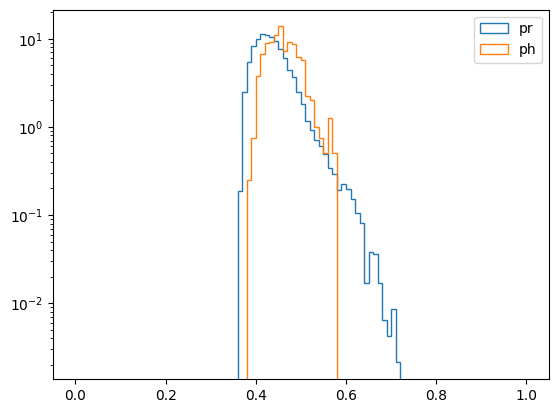

In [41]:
df_iforest['particle'] = np.where(df_iforest['index'] < num, 'pr', 'ph')
print(df_iforest.head(20))
print(df_iforest.tail(20))
print(len(df_iforest[df_iforest['particle'] == 'pr']))
print(len(df_iforest[df_iforest['particle'] == 'ph']))
print(len(df_iforest))
plt.hist(df_iforest[df_iforest['particle'] == 'pr']['iforest_score'], bins=100, label='pr', log=True, density=True, histtype='step', range=(0, 1))
plt.hist(df_iforest[df_iforest['particle'] == 'ph']['iforest_score'], bins=100, label='ph', log=True, density=True, histtype='step', range=(0, 1))
plt.legend()
plt.show()

(47000,) (400,)


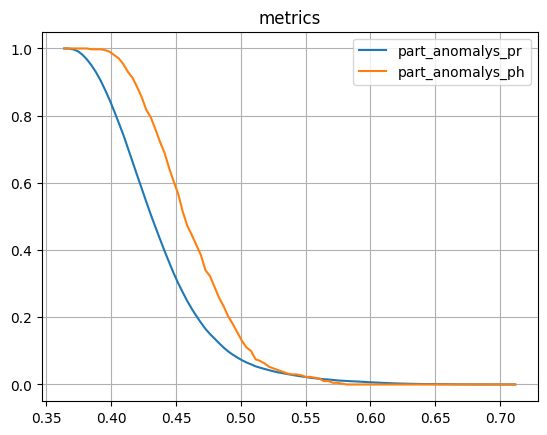

In [42]:
value = np.array(df_iforest['iforest_score'])
label_df = np.where(df_iforest['particle'] == 'pr', 0, 1)
score_samples = value[label_df == 0]
score_samples_photon = value[label_df == 1]
print(score_samples.shape, score_samples_photon.shape)
recall_list = []    
precision_list = []
f1_list = []
part_anomalys_pr_list = []
part_anomalys_ph_list = []
min_score = min(score_samples.min(), score_samples_photon.min())
max_score = max(score_samples.max(), score_samples_photon.max())
for th in np.linspace(min_score, max_score, 100):
    recall, precision, f1, part_anomalys_pr, part_anomalys_ph = get_metrics(score_samples, score_samples_photon, th)
    recall_list.append(recall)
    precision_list.append(precision)
    f1_list.append(f1)
    part_anomalys_pr_list.append(part_anomalys_pr)
    part_anomalys_ph_list.append(part_anomalys_ph)
# plt.plot(np.linspace(min_score, max_score, 100), recall_list, label='recall')
# plt.plot(np.linspace(min_score, max_score, 100), precision_list, label='precision')
# plt.plot(np.linspace(min_score, max_score, 100), f1_list, label='f1')
plt.plot(np.linspace(min_score, max_score, 100), part_anomalys_pr_list, label='part_anomalys_pr')
plt.plot(np.linspace(min_score, max_score, 100), part_anomalys_ph_list, label='part_anomalys_ph')
plt.legend()
plt.title('metrics')
plt.grid()

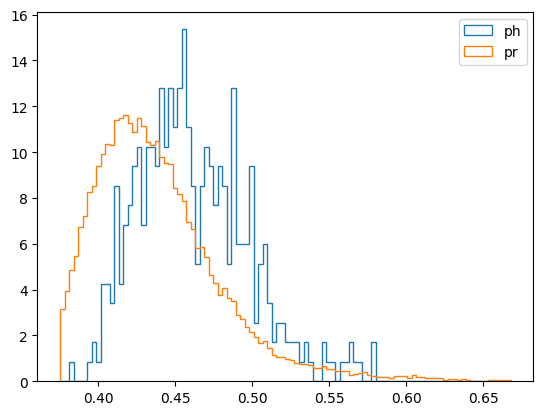

array([0.71162349, 0.70922992, 0.70756129, ..., 0.36577426, 0.36534651,
       0.36387672])

In [43]:
plt.hist(score_samples_photon, bins=100, label='ph', histtype='step', density=True, range=(0.375, 0.668))
plt.hist(score_samples, bins=100, label='pr', histtype='step', density=True, range=(0.375, 0.668))
plt.legend()
plt.show()
value


(array([ 0.        ,  0.        ,  0.85324232,  0.        ,  0.        ,
         0.        ,  0.85324232,  1.70648464,  0.85324232,  4.2662116 ,
         4.2662116 ,  3.41296928,  8.53242321,  4.2662116 ,  6.82593857,
         7.67918089,  9.38566553, 10.23890785,  6.82593857, 10.23890785,
        10.23890785,  9.38566553, 12.79863481, 10.23890785, 12.79863481,
        11.09215017, 12.79863481, 15.35836177, 11.09215017,  8.53242321,
         5.11945392,  8.53242321, 10.23890785,  9.38566553,  7.67918089,
         9.38566553,  8.53242321,  5.11945392, 12.79863481,  5.97269625,
         5.97269625,  5.97269625,  9.38566553,  2.55972696,  5.11945392,
         5.97269625,  3.41296928,  1.70648464,  2.55972696,  2.55972696,
         1.70648464,  1.70648464,  1.70648464,  0.85324232,  1.70648464,
         0.85324232,  0.        ,  0.        ,  1.70648464,  0.85324232,
         0.85324232,  0.        ,  0.85324232,  0.85324232,  1.70648464,
         0.85324232,  0.85324232,  0.        ,  0. 

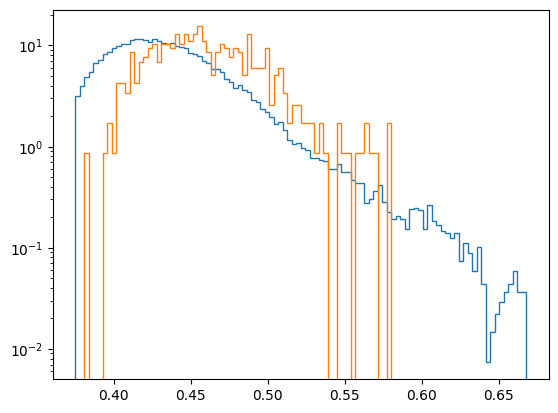

In [44]:
plt.hist(df_iforest[df_iforest['particle'] == 'pr']['iforest_score'], bins=100, label='pr', log=True, density=True, histtype='step', range=(0.375, 0.668))
plt.hist(df_iforest[df_iforest['particle'] == 'ph']['iforest_score'], bins=100, label='ph', log=True, density=True, histtype='step', range=(0.375, 0.668))


In [127]:
# KDE

In [45]:
from sklearn.neighbors import KernelDensity

In [47]:
num =47000
ch_emb = 6
num_ph = 400
print(f'part of data {num_ph/num}')
print('pr', embading_pr.shape, 'ph', embading_photon.shape)
index = np.random.randint(0, len(embading_pr), num)
index_ph = np.random.randint(0, len(embading_photon), num_ph)
# with recos

#feaches_pr = np.concatenate([embading_pr[index], num_det_pr[index].reshape(-1,1), recon_loss_pr[index].reshape(-1,1), recos_pr[index]], axis=1)

#feaches_photon = np.concatenate([embading_photon[index_ph], num_det_photon[index_ph].reshape(-1,1), recon_loss_photon[index_ph].reshape(-1,1), recos_photon[index_ph]], axis=1)

# without recos
feaches_pr = np.concatenate([embading_pr[index], num_det_pr[index].reshape(-1,1), recon_loss_pr[index].reshape(-1,1)], axis=1)

feaches_photon = np.concatenate([embading_photon[index_ph], num_det_photon[index_ph].reshape(-1,1), recon_loss_photon[index_ph].reshape(-1,1)], axis=1)

feaches = np.concatenate([feaches_pr, feaches_photon], axis=0)

label = np.concatenate([np.zeros(num), np.ones(num_ph)])

# shufle
shufle_index = np.random.permutation(len(feaches))
feaches = feaches[shufle_index]
label = label[shufle_index]

num_det_feaches = feaches[:,ch_emb]

print(feaches[:10], label[:10])

part of data 0.00851063829787234
pr (210315, 6) ph (210851, 6)
[[ 2.02569887e-01  3.52062076e-01 -1.01944661e+00  1.36310351e+00
   1.03550673e-01  1.02803397e+00  1.50000000e+01  5.87102911e-03]
 [ 1.72811604e+00  6.67437077e-01  8.32756281e-01 -9.10253346e-01
   1.83107138e-01  2.28093788e-01  8.00000000e+00  9.83920414e-04]
 [-3.31793427e-01  2.57853031e-01  8.53314936e-01 -4.22157049e-01
   1.08234835e+00  1.27239454e+00  1.20000000e+01  2.58577336e-03]
 [ 3.42081904e-01 -2.08956432e+00 -3.84841353e-01  4.73867744e-01
  -1.01573110e+00  1.18268418e+00  1.40000000e+01  1.59378012e-03]
 [ 8.88173580e-01  2.09860086e-01 -6.72657251e-01  1.83035463e-01
   6.71072721e-01 -9.13895249e-01  1.20000000e+01  4.28161211e-03]
 [ 2.16639042e+00  2.66503021e-02 -1.40878105e+00 -1.59441698e+00
   9.63510633e-01  1.24480598e-01  1.50000000e+01  9.20029765e-04]
 [ 7.58393705e-01 -1.18160772e+00 -2.38379277e-03  8.35139930e-01
   6.30963326e-01 -1.48021713e-01  1.10000000e+01  3.92144267e-03]
 [ 9.1

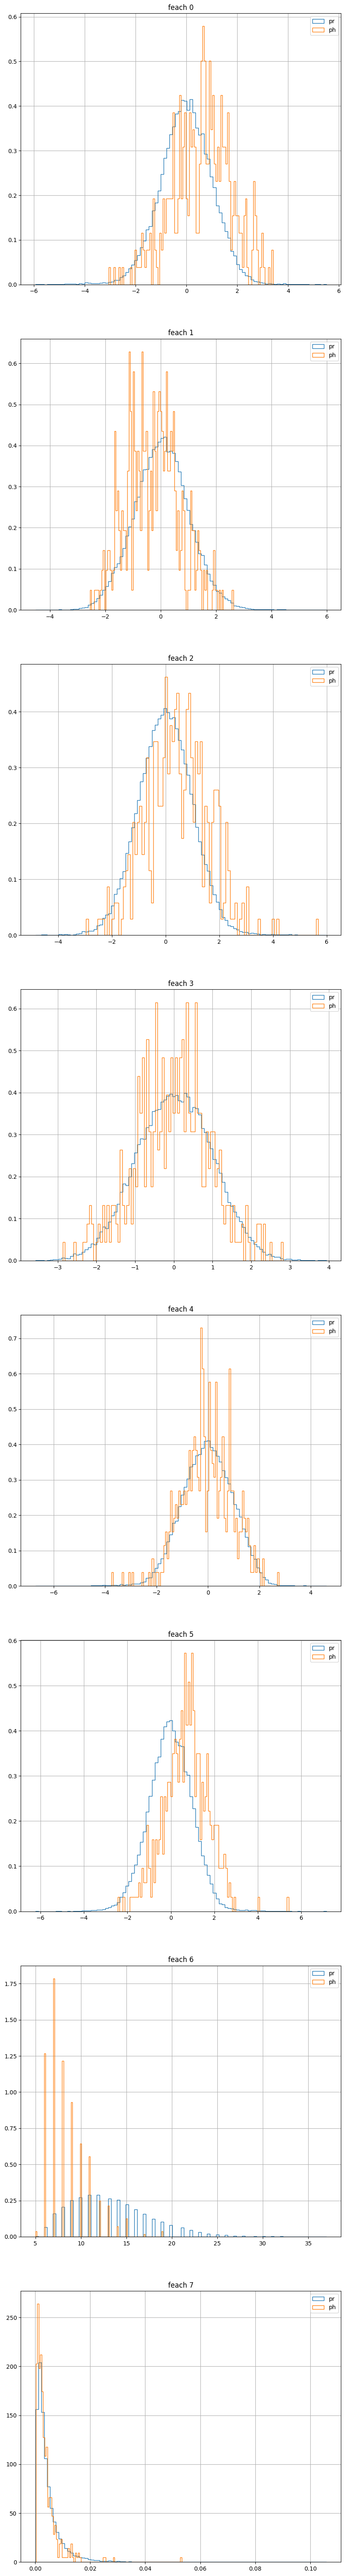

In [48]:

fig, ax = plt.subplots(feaches.shape[1],1, figsize=(10, feaches.shape[1]*10))
for i in range(feaches.shape[1]):
    ax[i].hist(feaches[label == 0,i], bins=100, label=f'pr', histtype='step', density=True)
    ax[i].hist(feaches[label == 1,i], bins=100, label=f'ph', histtype='step', density=True)
    ax[i].legend()
    ax[i].set_title(f'feach {i}')
    ax[i].grid()
plt.show()



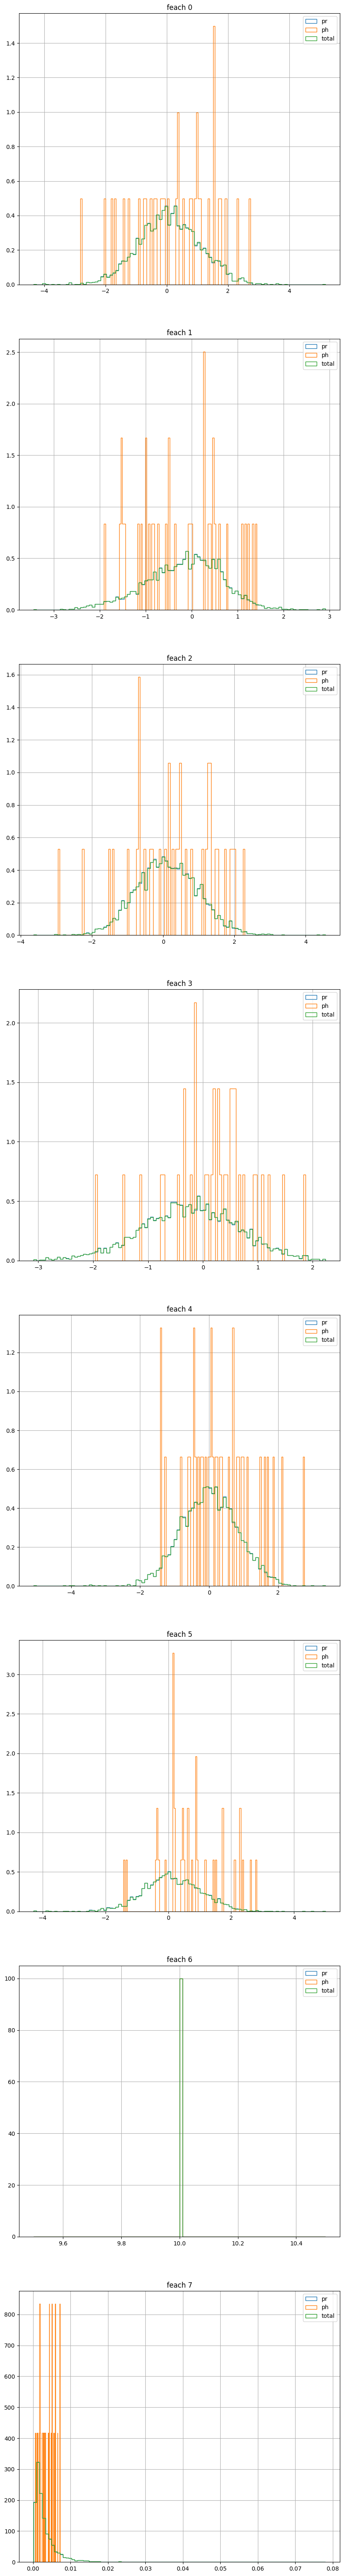

In [49]:
N=10
fig, ax = plt.subplots(feaches.shape[1],1, figsize=(10, feaches.shape[1]*10))
for i in range(feaches.shape[1]):
    ax[i].hist(feaches[label == 0,i][num_det_feaches[label == 0] == N], bins=100, label=f'pr', histtype='step', density=True)
    ax[i].hist(feaches[label == 1,i][num_det_feaches[label == 1] == N], bins=100, label=f'ph', histtype='step', density=True)
    ax[i].hist(feaches[:,i][num_det_feaches == N], bins=100, label=f'total', histtype='step', density=True)
    ax[i].legend()
    ax[i].set_title(f'feach {i}')
    ax[i].grid()
plt.show()

In [51]:
feaches_pr[feaches_pr[:,6] == N, 7].shape

(4095,)

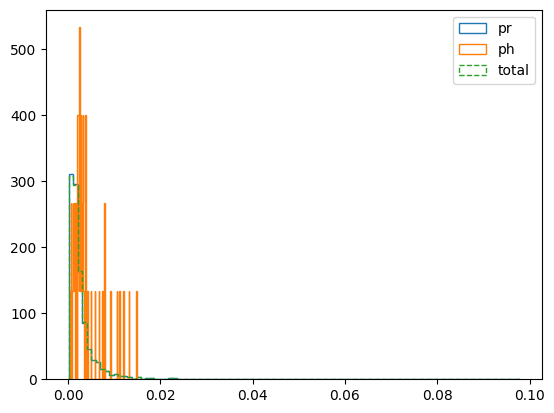

In [52]:
N = 9
plt.hist(feaches_pr[feaches_pr[:,ch_emb] == N, 7], bins=100, label='pr', histtype='step', density=True)
plt.hist(feaches_photon[feaches_photon[:,ch_emb] == N, 7], bins=100, label='ph', histtype='step', density=True)
plt.hist(feaches[feaches[:,ch_emb] == N, 7], bins=100, label='total', histtype='step', density=True, linestyle='--')
plt.legend()
plt.show()

(4095, 8) (36, 8)


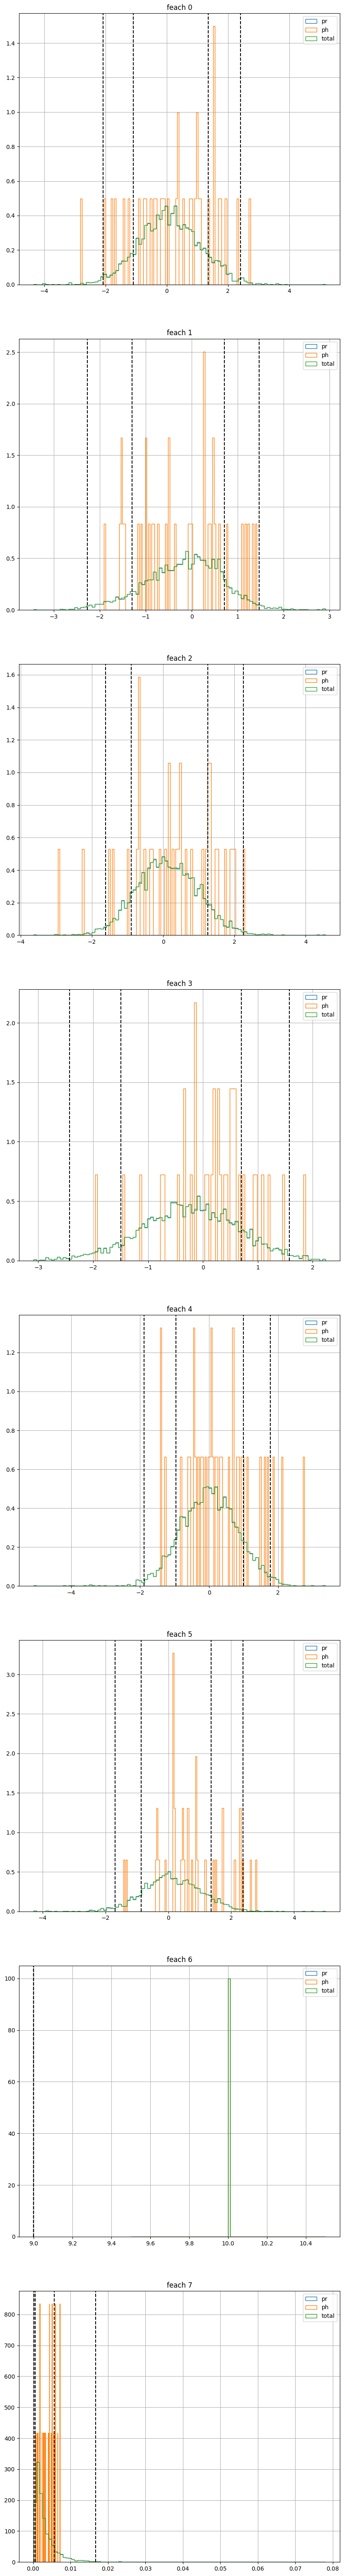

In [53]:
# quantile
quan_list = [0.01, 0.1, 0.9, 0.99]
quantile_feaches = np.quantile(feaches[num_det_feaches == N], quan_list, axis=0)
N=10
fig, ax = plt.subplots(feaches.shape[1],1, figsize=(10, feaches.shape[1]*10))
for i in range(feaches.shape[1]):
    ax[i].hist(feaches[label == 0,i][num_det_feaches[label == 0] == N], bins=100, label=f'pr', histtype='step', density=True)
    ax[i].hist(feaches[label == 1,i][num_det_feaches[label == 1] == N], bins=100, label=f'ph', histtype='step', density=True)
    ax[i].hist(feaches[:,i][num_det_feaches == N], bins=100, label=f'total', histtype='step', density=True)
    ax[i].legend()
    for j in range(quantile_feaches.shape[0]):
        ax[i].axvline(quantile_feaches[j,i], color='k', linestyle='--', label=f'quan {quan_list[j]}')
    ax[i].set_title(f'feach {i}')
    
    ax[i].grid()
pr = feaches[label == 0,:][num_det_feaches[label == 0] == N]
ph = feaches[label == 1,:][num_det_feaches[label == 1] == N]
print(pr.shape, ph.shape)


In [60]:
ch_emb= 6
X = feaches[:][num_det_feaches == N].copy()
X = np.concatenate([X[:,:ch_emb], X[:,ch_emb+1:]], axis=1)
print(X.shape)
# Лучше RobustScaler, чем StandardScaler, для задач с выбросами
scaler = RobustScaler()
X_scaled = scaler.fit_transform(X)
X_scaled
label_X = label[num_det_feaches == N]
print('pr',(label_X == 0).sum(), 'ph', (label_X == 1).sum())
# feaches = X_scaled

(4131, 7)
pr 4095 ph 36


-6.421288613981038 -7.100118406303867
0.6545787527641499 0.0


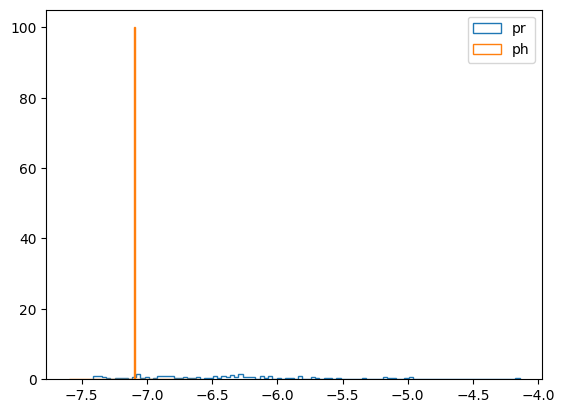

In [68]:
# kde

bandwidth = 0.35

num=100
index = np.random.randint(0, len(X_scaled), num)
kde = KernelDensity(bandwidth=bandwidth).fit(X_scaled)


scores = kde.score_samples(X_scaled[index])
label_scores = label_X[index]

plt.hist(scores[label_scores == 0], bins=100, label='pr', histtype='step', density=True,)
plt.hist(scores[label_scores == 1], bins=100, label='ph', histtype='step', density=True,)
print(scores[label_scores == 0].mean(), scores[label_scores == 1].mean())
print(scores[label_scores == 0].std(), scores[label_scores == 1].std())
plt.legend()
plt.show()




-6.420877686646742 -7.145980514357419
0.6557217163877522 0.3187303447285529


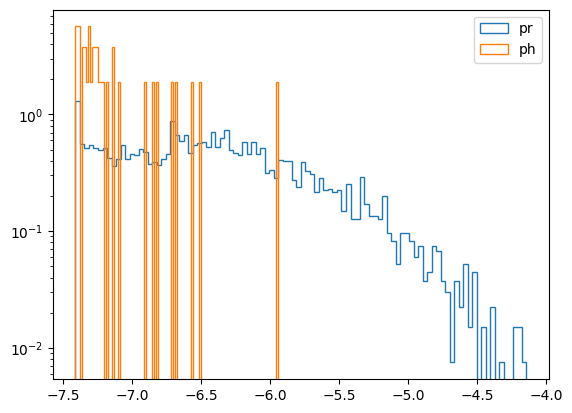

In [69]:
scores_pr = kde.score_samples(X_scaled[label_X == 0])
scores_ph = kde.score_samples(X_scaled[label_X == 1])
print(scores_pr.mean(), scores_ph.mean())
print(scores_pr.std(), scores_ph.std())
plt.hist(scores_pr, bins=100, label='pr', histtype='step', density=True, log=True)
plt.hist(scores_ph, bins=100, label='ph', histtype='step', density=True, log=True)
plt.legend()

-6.420877686646742 -7.145980514357419
0.6557217163877522 0.3187303447285529


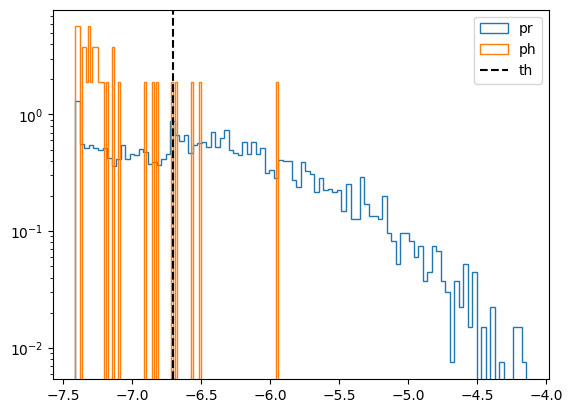

In [71]:
th=-6.7
scores_pr = kde.score_samples(X_scaled[label_X == 0])
scores_ph = kde.score_samples(X_scaled[label_X == 1])
print(scores_pr.mean(), scores_ph.mean())
print(scores_pr.std(), scores_ph.std())
plt.hist(scores_pr, bins=100, label='pr', histtype='step', density=True, log=True)
plt.hist(scores_ph, bins=100, label='ph', histtype='step', density=True, log=True)
plt.axvline(th, color='k', linestyle='--', label=f'th')
plt.legend()

In [72]:
def show_del_by_score(pr, ph, use_ph=True, n_ph=1, density_ph = None, density_pr = None, th = 0.1):
    # pr_index= np.random.randint(0, pr.shape[0], size=5000)
    # ph_index= np.random.randint(0, ph.shape[0], size=5000)
    # pr = pr[pr_index]
    # ph = ph[ph_index]
    fig = plt.subplot()
    plt.hist(density_pr, bins=100, label='pr', histtype='step', density=True, log=True)
    plt.hist(density_ph, bins=100, label='ph', histtype='step', density=True, log=True)
    plt.axvline(th, color='k', linestyle='--', label=f'th')
    plt.legend()
    plt.show()
    fig, ax = plt.subplots(2,3, figsize=(12, 12))
    ax_1, ax_2, ax_3 = ax[0]
    reducer = umap.UMAP(n_components=2)
    if use_ph:
        manifold = reducer.fit(np.concatenate([pr, ph[::n_ph]], axis=0))
    else:
        manifold = reducer.fit(pr)
    X_pr = manifold.transform(pr)
    X_ph = manifold.transform(ph)

    X_all = np.vstack([X_pr, X_ph[::n_ph]])

    kde = gaussian_kde(X_all.T, )
    x_min, x_max = X_all[:, 0].min() - 1, X_all[:, 0].max() + 1
    y_min, y_max = X_all[:, 1].min() - 1, X_all[:, 1].max() + 1
    grid_x, grid_y = np.mgrid[x_min:x_max:100j, y_min:y_max:100j]
    density = kde(np.vstack([grid_x.ravel(), grid_y.ravel()]))
    density = density.reshape(grid_x.shape)
    cmap = plt.colormaps['PiYG']
    # (1,0) - плотность для всех точек
    im = ax[0, 2].pcolormesh(grid_x, grid_y, density, cmap=cmap)
    ax[0, 2].set_title('Density (all)')
    fig.colorbar(im, ax=ax[0, 2], label='Density')

    im = ax[1, 2].pcolormesh(grid_x, grid_y, density, cmap=cmap)
    ax[1, 2].set_title('Density (all)')
    fig.colorbar(im, ax=ax[1, 2], label='Density')

    ax_1, ax_2, ax_3 = ax[0]
    ax_1.scatter(X_pr[:, 0], X_pr[:, 1], s=0.5, alpha=0.3, label='pr')
    ax_2.scatter(X_ph[:, 0], X_ph[:, 1], s=0.5, alpha=0.3, label='ph')
    ax_3.scatter(X_pr[:, 0], X_pr[:, 1], s=0.5, alpha=0.3, label='pr')
    ax_3.scatter(X_ph[:, 0], X_ph[:, 1], s=0.5, alpha=0.3, label='ph')
    ax_1.legend()
    ax_2.legend()
    ax_3.legend()

    pr_index = density_pr<th
    ph_index = density_ph<th
    print(len(density_pr), len(density_ph))
    print(pr_index.sum(), ph_index.sum())
    print(len(X_pr[pr_index, 0]), len(X_ph[ph_index, 0]))
    ax_1, ax_2, ax_3 = ax[1]
    ax_1.scatter(X_pr[pr_index, 0], X_pr[pr_index, 1], s=0.5, alpha=0.3, label='pr')
    ax_2.scatter(X_ph[ph_index, 0], X_ph[ph_index, 1], s=0.5, alpha=0.3, label='ph')
    ax_3.scatter(X_pr[pr_index, 0], X_pr[pr_index, 1], s=0.5, alpha=0.3, label='pr')
    ax_3.scatter(X_ph[ph_index, 0], X_ph[ph_index, 1], s=0.5, alpha=0.3, label='ph')
    
    # ax[1,1].hist(density_ph, bins=100, label='ph', histtype='step', density=True, log=True)
    # ax[1,1].hist(density_pr, bins=100, label='pr', histtype='step', density=True, log=True)
    # ax[1,1].legend()
    # ax[1,1].set_title('Density (ph and pr)')
    # ax[1,1].grid()

    plt.tight_layout()
    plt.show()

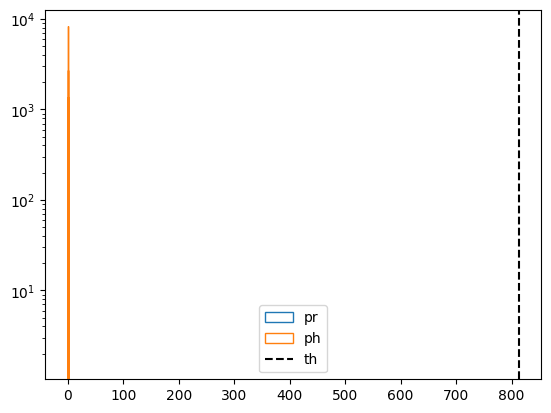

4095 36
4095 36
4095 36


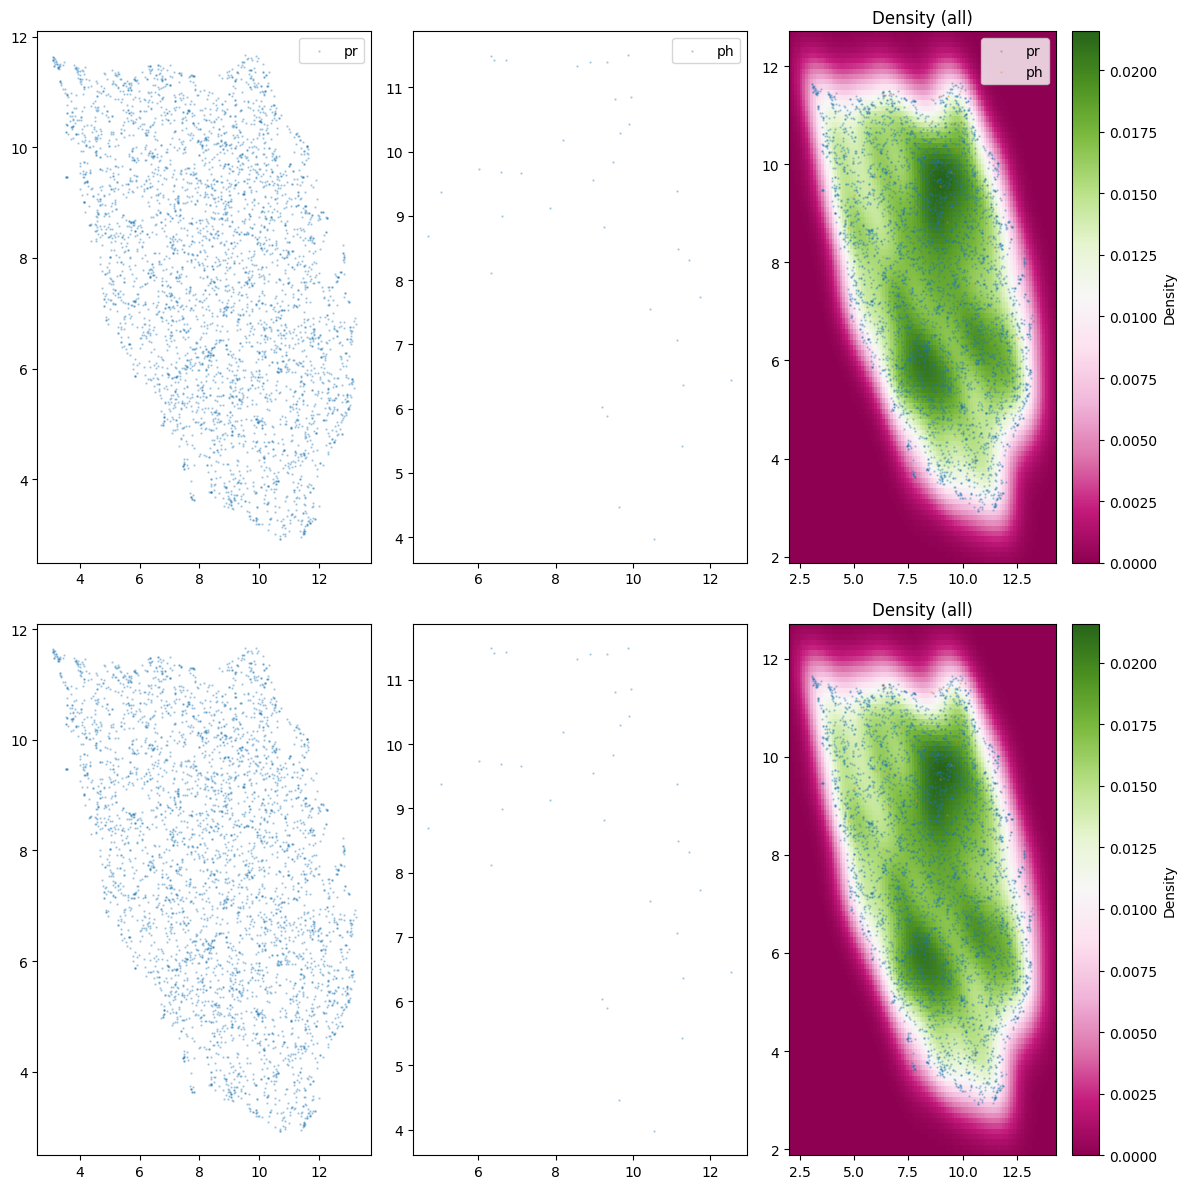

In [73]:
th = -6.7
show_del_by_score(X_scaled[label_X == 0], X_scaled[label_X == 1], n_ph=1, density_ph=np.exp(scores_ph), density_pr=np.exp(scores_pr), th=np.exp(-th))

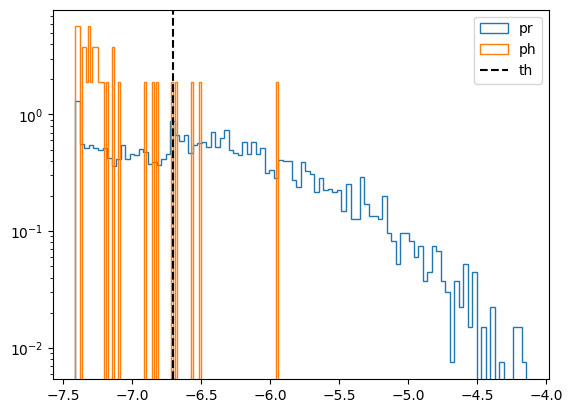

4095 36
1504 32
1504 32


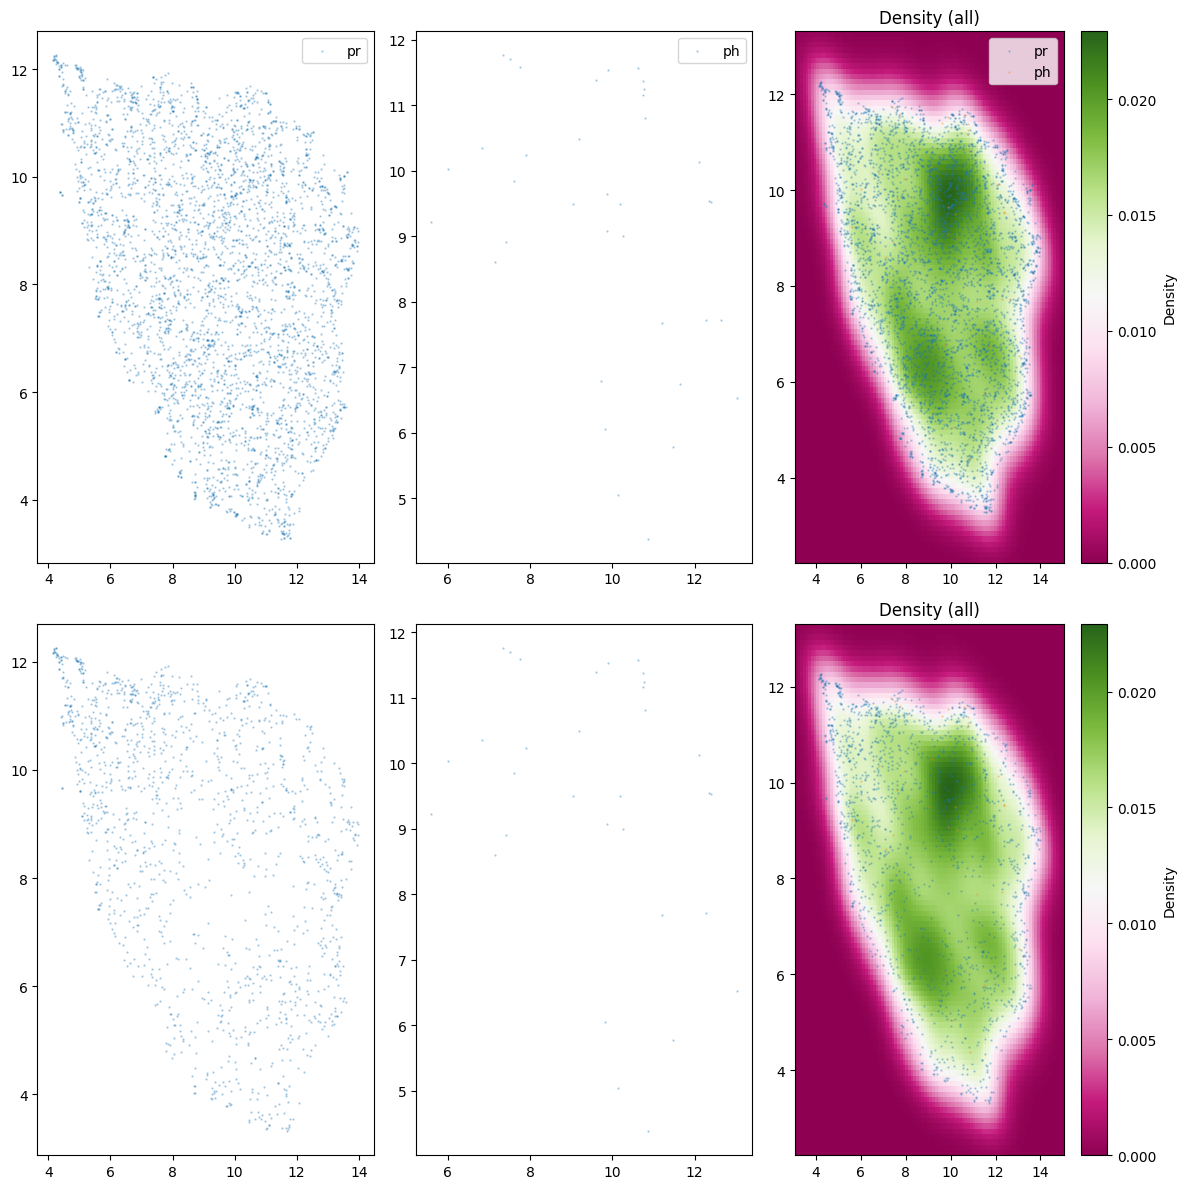

In [74]:
show_del_by_score(X_scaled[label_X == 0], X_scaled[label_X == 1], n_ph=1, density_ph=scores_ph, density_pr=scores_pr, th=-6.7)

In [182]:
# Полный прогоне KDE 

# Полный прогоне KDE 

In [75]:
print(len(embading_pr), len(embading_photon))

210315 210851


In [76]:
np.where(num_det_pr == N)[0].shape

(18391,)

part of data 0.01
pr (210315, 6) ph (210851, 6)
(10939, 7)
pr 10476 ph 463
-6.03973793402203 -6.976157430333174
0.7080336563713638 0.44979514717048596


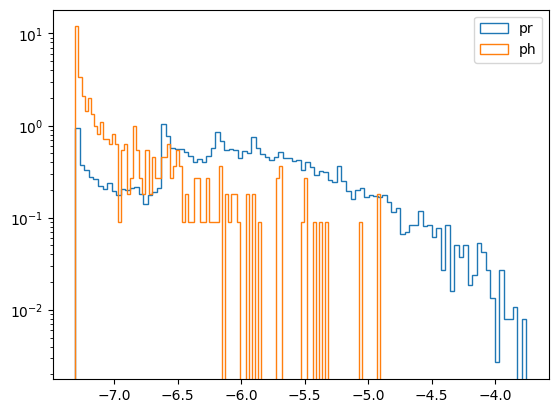

In [82]:

num =200000
num_ph = 2000
N = 7
bandwidth = 0.3
print(f'part of data {num_ph/num}')
print('pr', embading_pr.shape, 'ph', embading_photon.shape)
index = np.random.randint(0, len(embading_pr), num)
index_ph = np.random.randint(0, len(embading_photon), num_ph)
# with recos

index_pr_N_det = np.where(num_det_pr == N)[0]
index_ph_N_det = np.where(num_det_photon == N)[0]

# without recos
feaches_pr = np.concatenate([embading_pr[index], num_det_pr[index].reshape(-1,1), recon_loss_pr[index].reshape(-1,1)], axis=1)

feaches_photon = np.concatenate([embading_photon[index_ph], num_det_photon[index_ph].reshape(-1,1), recon_loss_photon[index_ph].reshape(-1,1)], axis=1)

feaches = np.concatenate([feaches_pr, feaches_photon], axis=0)

label = np.concatenate([np.zeros(num), np.ones(num_ph)])

# shufle
shufle_index = np.random.permutation(len(feaches))
feaches = feaches[shufle_index]
label = label[shufle_index]

num_det_feaches = feaches[:,ch_emb]



X = feaches[:][num_det_feaches == N].copy()
X = np.concatenate([X[:,:ch_emb], X[:,ch_emb+1:]], axis=1)
print(X.shape)
# Лучше RobustScaler, чем StandardScaler, для задач с выбросами
scaler = RobustScaler()
X_scaled = scaler.fit_transform(X)
X_scaled
label_X = label[num_det_feaches == N]
print('pr',(label_X == 0).sum(), 'ph', (label_X == 1).sum())


num=100
index = np.random.randint(0, len(X_scaled), num)
kde = KernelDensity(bandwidth=bandwidth).fit(X_scaled)


scores = kde.score_samples(X_scaled[index])
label_scores = label_X[index]

scores_pr = kde.score_samples(X_scaled[label_X == 0])
scores_ph = kde.score_samples(X_scaled[label_X == 1])
print(scores_pr.mean(), scores_ph.mean())
print(scores_pr.std(), scores_ph.std())
plt.hist(scores_pr, bins=100, label='pr', histtype='step', density=True, log=True)
plt.hist(scores_ph, bins=100, label='ph', histtype='step', density=True, log=True)
plt.legend()

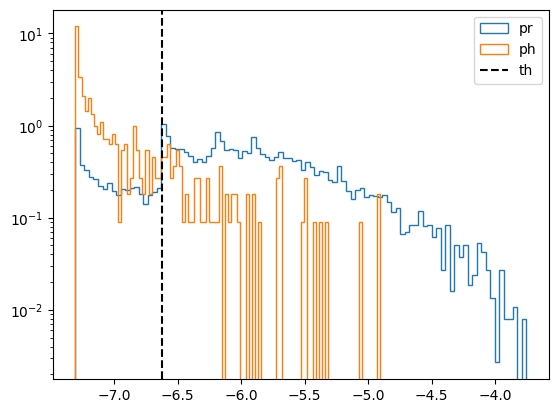

In [86]:
th=-6.62
plt.hist(scores_pr, bins=100, label='pr', histtype='step', density=True, log=True)
plt.hist(scores_ph, bins=100, label='ph', histtype='step', density=True, log=True)
plt.axvline(th, color='k', linestyle='--', label=f'th')
plt.legend()

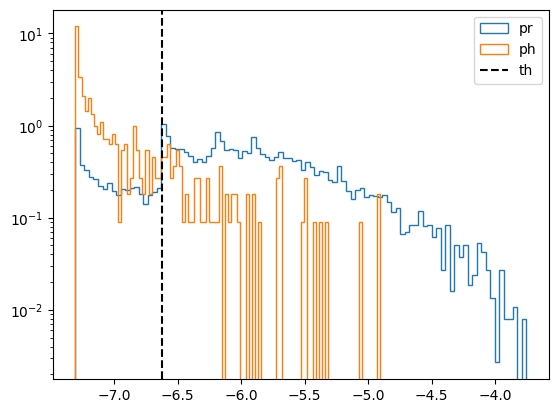

10476 463
1858 377
1858 377


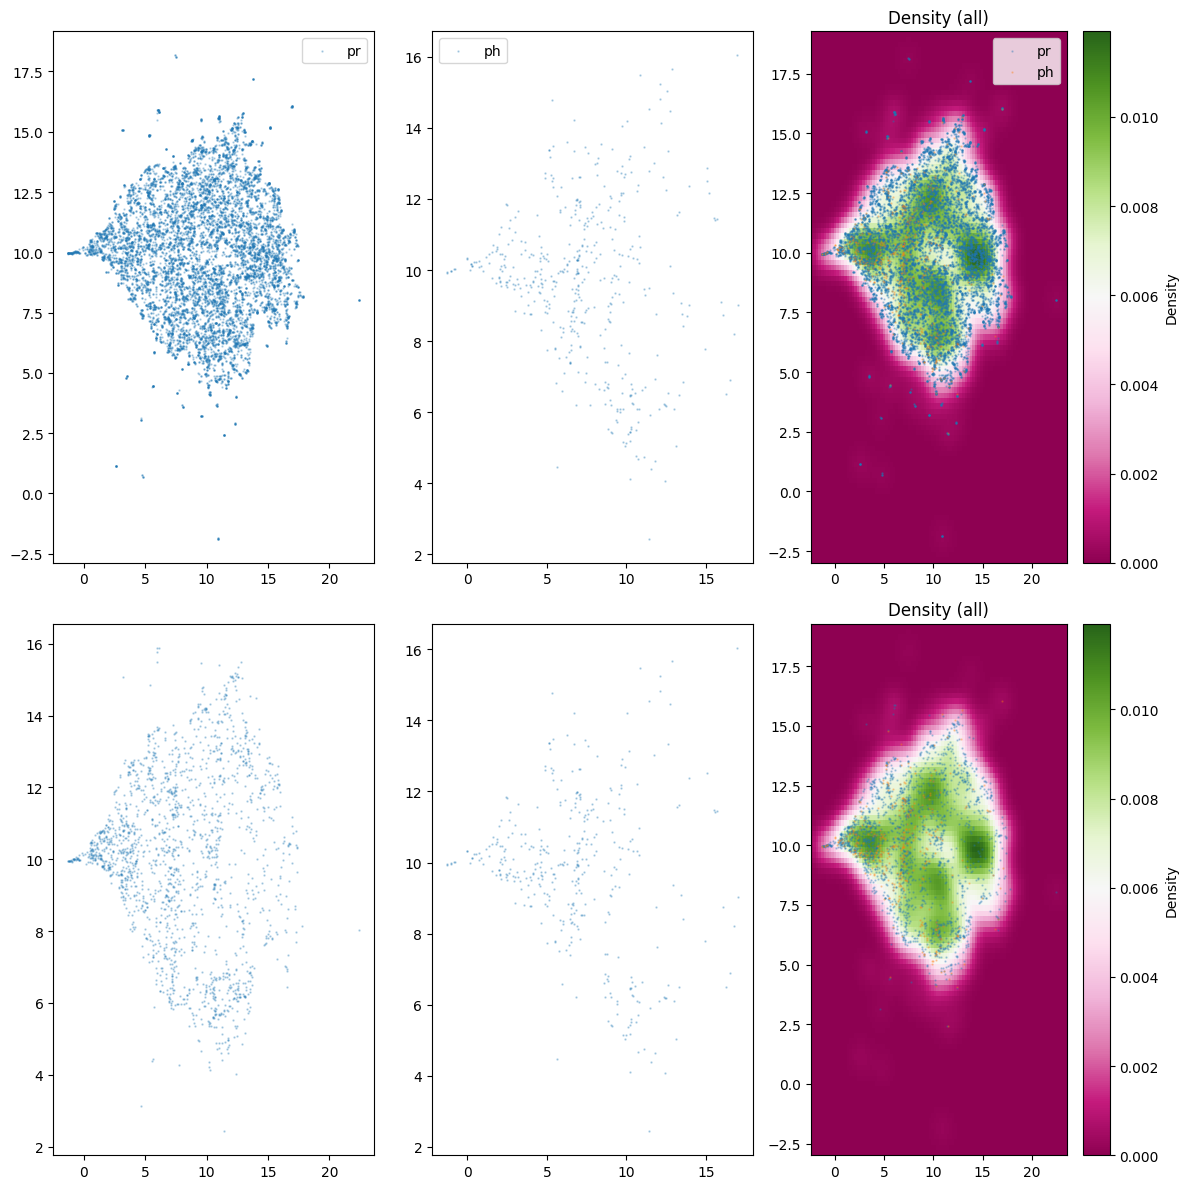

In [87]:
show_del_by_score(X_scaled[label_X == 0], X_scaled[label_X == 1], n_ph=1, density_ph=scores_ph, density_pr=scores_pr, th=-6.62)

# 17.7% protons
# 81.4% photons

In [ ]:
th=-8.9
show_del_by_score(X_scaled[label_X == 0], X_scaled[label_X == 1], n_ph=1, density_ph=scores_ph, density_pr=scores_pr, th=th)

10376 458
2684 304
2684 304

10357 484
1449 212
1449 212

In [92]:
# Проверка на востановление recos из латентного пространства
from catboost import CatBoostRegressor
latent_pr = embading_pr.copy()
latent_photon = embading_photon.copy()
print(latent_pr.shape, latent_photon.shape, recos_pr.shape, recos_photon.shape)

(210315, 6) (210851, 6) (210315, 15) (210851, 15)


In [93]:
#test-train split
import sklearn
from sklearn.model_selection import train_test_split
latent_pr_train, latent_pr_test, recos_pr_train, recos_pr_test = train_test_split(latent_pr, recos_pr, test_size=0.2, random_state=42)
latent_photon_train, latent_photon_test, recos_photon_train, recos_photon_test = train_test_split(latent_photon, recos_photon, test_size=0.2, random_state=42)



In [97]:
regressor = CatBoostRegressor(n_estimators=1000, learning_rate=0.05, depth=10, random_seed=42,
loss_function='MultiRMSE', eval_metric='MultiRMSE', early_stopping_rounds=20)
regressor.fit(latent_pr_train, recos_pr_train, eval_set=(latent_pr_test, recos_pr_test), use_best_model=True)




0:	learn: 3.8767503	test: 3.8668457	best: 3.8668457 (0)	total: 245ms	remaining: 4m 4s
1:	learn: 3.8764072	test: 3.8668856	best: 3.8668457 (0)	total: 509ms	remaining: 4m 13s
2:	learn: 3.8761535	test: 3.8668897	best: 3.8668457 (0)	total: 763ms	remaining: 4m 13s
3:	learn: 3.8758908	test: 3.8669248	best: 3.8668457 (0)	total: 997ms	remaining: 4m 8s
4:	learn: 3.8755514	test: 3.8669188	best: 3.8668457 (0)	total: 1.24s	remaining: 4m 7s
5:	learn: 3.8752395	test: 3.8669281	best: 3.8668457 (0)	total: 1.5s	remaining: 4m 8s
6:	learn: 3.8750008	test: 3.8669561	best: 3.8668457 (0)	total: 1.77s	remaining: 4m 11s
7:	learn: 3.8746971	test: 3.8669702	best: 3.8668457 (0)	total: 2.04s	remaining: 4m 13s
8:	learn: 3.8743731	test: 3.8670063	best: 3.8668457 (0)	total: 2.28s	remaining: 4m 10s
9:	learn: 3.8740308	test: 3.8670228	best: 3.8668457 (0)	total: 2.52s	remaining: 4m 9s
10:	learn: 3.8737628	test: 3.8670227	best: 3.8668457 (0)	total: 2.74s	remaining: 4m 6s
11:	learn: 3.8734312	test: 3.8670451	best: 3.8668

In [ ]:
regressor.

## ПРогон KDE с recos

part of data 0.01
pr (210315, 6) ph (210851, 6)
(202000, 23)




In [89]:

num =200000
num_ph = 2000
N = 7
bandwidth = 0.41
print(f'part of data {num_ph/num}')
print('pr', embading_pr.shape, 'ph', embading_photon.shape)
index = np.random.randint(0, len(embading_pr), num)
index_ph = np.random.randint(0, len(embading_photon), num_ph)
# with recos

feaches_pr = np.concatenate([embading_pr[index], num_det_pr[index].reshape(-1,1), recon_loss_pr[index].reshape(-1,1)], axis=1)

feaches_photon = np.concatenate([embading_photon[index_ph], num_det_photon[index_ph].reshape(-1,1), recon_loss_photon[index_ph].reshape(-1,1)], axis=1)

# add recos
feaches_pr = np.concatenate([feaches_pr, recos_pr[index]], axis=1)
feaches_photon = np.concatenate([feaches_photon, recos_photon[index_ph]], axis=1)


feaches = np.concatenate([feaches_pr, feaches_photon], axis=0)

label = np.concatenate([np.zeros(num), np.ones(num_ph)])

# shufle
shufle_index = np.random.permutation(len(feaches))
feaches = feaches[shufle_index]
label = label[shufle_index]

num_det_feaches = feaches[:,ch_emb]

print(feaches.shape)
fig, ax = plt.subplots(feaches.shape[1],1, figsize=(10, feaches.shape[1]*10))
for i in range(feaches.shape[1]):
    ax[i].hist(feaches[label == 0,i], bins=100, label=f'pr', histtype='step', density=True)
    ax[i].hist(feaches[label == 1,i], bins=100, label=f'ph', histtype='step', density=True)
    ax[i].legend()
    ax[i].set_title(f'feach {i}')
    ax[i].grid()
plt.show()

part of data 0.01
pr (210315, 8) ph (210851, 8)
[[ 4.34671849e-01  4.49277103e-01  2.28105724e-01  5.41433513e-01
  -1.10380065e+00 -1.11490464e+00 -8.64692450e-01 -1.02637076e+00
   9.00000000e+00  6.66710315e-03  1.38128757e+00  6.84225783e-02
  -1.02817282e-01  7.56021500e-01]
 [-5.85101843e-01  1.77080691e+00  8.62918913e-01 -4.14451182e-01
   1.68913400e+00  1.31564379e+00 -7.44193077e-01  1.19321674e-01
   1.00000000e+01  6.87978324e-03 -7.46476114e-01 -1.29246199e+00
   1.16859007e+00  8.00965905e-01]
 [-2.49369711e-01  8.18214774e-01 -3.97974439e-03  3.63665879e-01
   1.54659307e+00  3.77776682e-01 -1.55828297e+00  9.90129590e-01
   1.10000000e+01  4.79980884e-03  8.86704445e-01  2.63838738e-01
  -4.11055982e-01 -3.48720312e-01]
 [-1.95486927e+00 -1.07884419e+00 -1.34793437e+00  2.75565922e-01
   7.06481695e-01 -1.16176713e+00  1.46287382e-01 -1.04862607e+00
   1.70000000e+01  7.17344414e-03  8.79210755e-02 -7.15842903e-01
   1.56210721e+00  1.28701925e+00]
 [ 1.71147394e+00  3

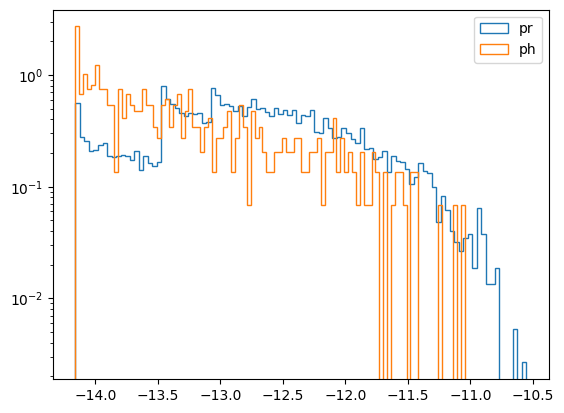

In [59]:
num =200000
num_ph = 2000
N = 7
recos_last = -4
bandwidth = 0.58
print(f'part of data {num_ph/num}')
print('pr', embading_pr.shape, 'ph', embading_photon.shape)
index = np.random.randint(0, len(embading_pr), num)
index_ph = np.random.randint(0, len(embading_photon), num_ph)
# with recos

index_pr_N_det = np.where(num_det_pr == N)[0]
index_ph_N_det = np.where(num_det_photon == N)[0]

# without recos
feaches_pr = np.concatenate([embading_pr[index], num_det_pr[index].reshape(-1,1), recon_loss_pr[index].reshape(-1,1)], axis=1)

feaches_photon = np.concatenate([embading_photon[index_ph], num_det_photon[index_ph].reshape(-1,1), recon_loss_photon[index_ph].reshape(-1,1)], axis=1)

# add recos
feaches_pr = np.concatenate([feaches_pr, recos_pr[index, :-recos_last]], axis=1)
feaches_photon = np.concatenate([feaches_photon, recos_photon[index_ph, :-recos_last]], axis=1)



feaches = np.concatenate([feaches_pr, feaches_photon], axis=0)

label = np.concatenate([np.zeros(num), np.ones(num_ph)])

# shufle
shufle_index = np.random.permutation(len(feaches))
feaches = feaches[shufle_index]
label = label[shufle_index]

num_det_feaches = feaches[:,8]

print(feaches[:10], label[:10])


X = feaches[:][num_det_feaches == N].copy()
X = np.concatenate([X[:,:8], X[:,9:]], axis=1)
print(X.shape)
# Лучше RobustScaler, чем StandardScaler, для задач с выбросами
scaler = RobustScaler()
X_scaled = scaler.fit_transform(X)
X_scaled
label_X = label[num_det_feaches == N]
print('pr',(label_X == 0).sum(), 'ph', (label_X == 1).sum())


num=100
index = np.random.randint(0, len(X_scaled), num)
kde = KernelDensity(bandwidth=bandwidth).fit(X_scaled)


scores = kde.score_samples(X_scaled[index])
label_scores = label_X[index]

scores_pr = kde.score_samples(X_scaled[label_X == 0])
scores_ph = kde.score_samples(X_scaled[label_X == 1])
print(scores_pr.mean(), scores_ph.mean())
print(scores_pr.std(), scores_ph.std())
plt.hist(scores_pr, bins=100, label='pr', histtype='step', density=True, log=True)
plt.hist(scores_ph, bins=100, label='ph', histtype='step', density=True, log=True)
plt.legend()

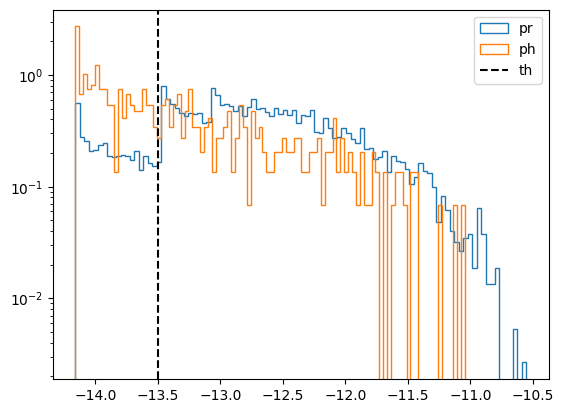

10407 472
1509 227
1509 227


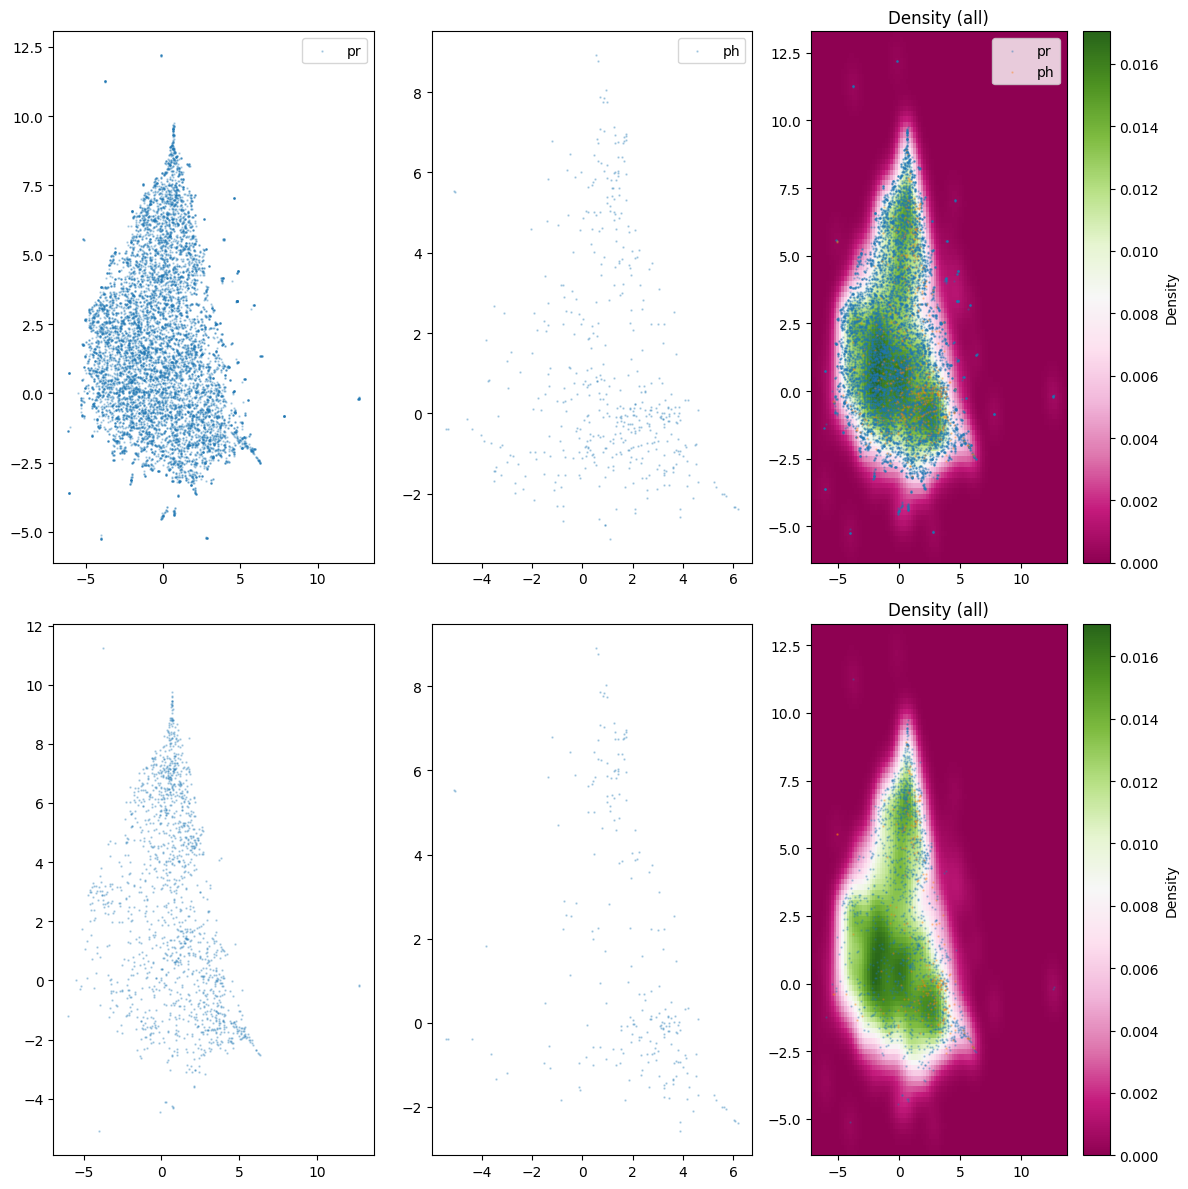

In [60]:
th=-13.5
show_del_by_score(X_scaled[label_X == 0], X_scaled[label_X == 1], n_ph=1, density_ph=scores_ph, density_pr=scores_pr, th=th)

In [70]:
def show_del_by_score_only_KDE_MAP(pr, ph, use_ph=True, n_ph=1, density_ph = None, density_pr = None, th = 0.1):
    # pr_index= np.random.randint(0, pr.shape[0], size=5000)
    # ph_index= np.random.randint(0, ph.shape[0], size=5000)
    # pr = pr[pr_index]
    # ph = ph[ph_index]
    fig = plt.subplot()
    plt.hist(density_pr, bins=100, label='pr', histtype='step', density=True, log=True)
    plt.hist(density_ph, bins=100, label='ph', histtype='step', density=True, log=True)
    plt.axvline(th, color='k', linestyle='--', label=f'th')
    plt.legend()
    plt.title('Density (pr and ph)')
    plt.xlabel('log probability')
    plt.ylabel('log density')
    plt.show()
    fig, ax = plt.subplots(1,2, figsize=(12, 12))
    ax_3 = ax[0]
    reducer = umap.UMAP(n_components=2)
    if use_ph:
        manifold = reducer.fit(np.concatenate([pr, ph[::n_ph]], axis=0))
    else:
        manifold = reducer.fit(pr)
    X_pr = manifold.transform(pr)
    X_ph = manifold.transform(ph)

    X_all = np.vstack([X_pr, X_ph[::n_ph]])

    kde = gaussian_kde(X_all.T, )
    x_min, x_max = X_all[:, 0].min() - 1, X_all[:, 0].max() + 1
    y_min, y_max = X_all[:, 1].min() - 1, X_all[:, 1].max() + 1
    grid_x, grid_y = np.mgrid[x_min:x_max:100j, y_min:y_max:100j]
    density = kde(np.vstack([grid_x.ravel(), grid_y.ravel()]))
    density = density.reshape(grid_x.shape)
    cmap = plt.colormaps['PiYG']
    # (1,0) - плотность для всех точек
    im = ax[0].pcolormesh(grid_x, grid_y, density, cmap=cmap)
    ax[0].set_title('All Data')
    fig.colorbar(im, ax=ax[0], label='Density')

    im = ax[1].pcolormesh(grid_x, grid_y, density, cmap=cmap)
    ax[1].set_title('Anomaly Data')
    fig.colorbar(im, ax=ax[1], label='Density')

    ax_3 = ax[0]
    ax_3.scatter(X_pr[:, 0], X_pr[:, 1], s=1, alpha=0.3, label='pr')
    ax_3.scatter(X_ph[:, 0], X_ph[:, 1], s=1, alpha=0.3, label='ph')
    ax_1.legend()
    ax_2.legend()
    ax_3.legend()

    pr_index = density_pr<th
    ph_index = density_ph<th
    print(len(density_pr), len(density_ph))
    print(pr_index.sum(), ph_index.sum())
    print(len(X_pr[pr_index, 0]), len(X_ph[ph_index, 0]))
    ax_3 = ax[1]
    ax_3.scatter(X_pr[pr_index, 0], X_pr[pr_index, 1], s=3, alpha=0.3, label='pr')
    ax_3.scatter(X_ph[ph_index, 0], X_ph[ph_index, 1], s=3, alpha=0.3, label='ph')
    
    # ax[1,1].hist(density_ph, bins=100, label='ph', histtype='step', density=True, log=True)
    # ax[1,1].hist(density_pr, bins=100, label='pr', histtype='step', density=True, log=True)
    # ax[1,1].legend()
    # ax[1,1].set_title('Density (ph and pr)')
    # ax[1,1].grid()

    plt.tight_layout()
    plt.show()

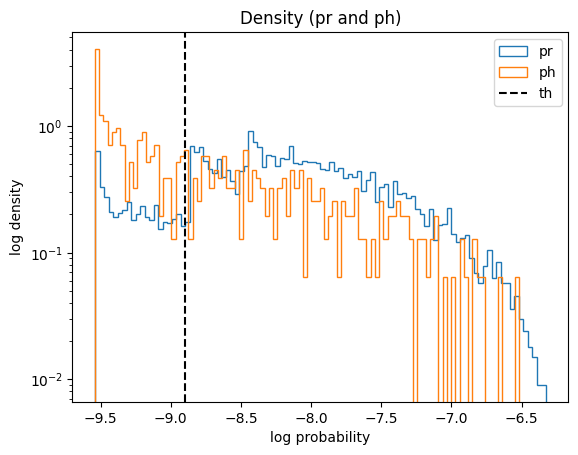

10358 514
1516 257
1516 257


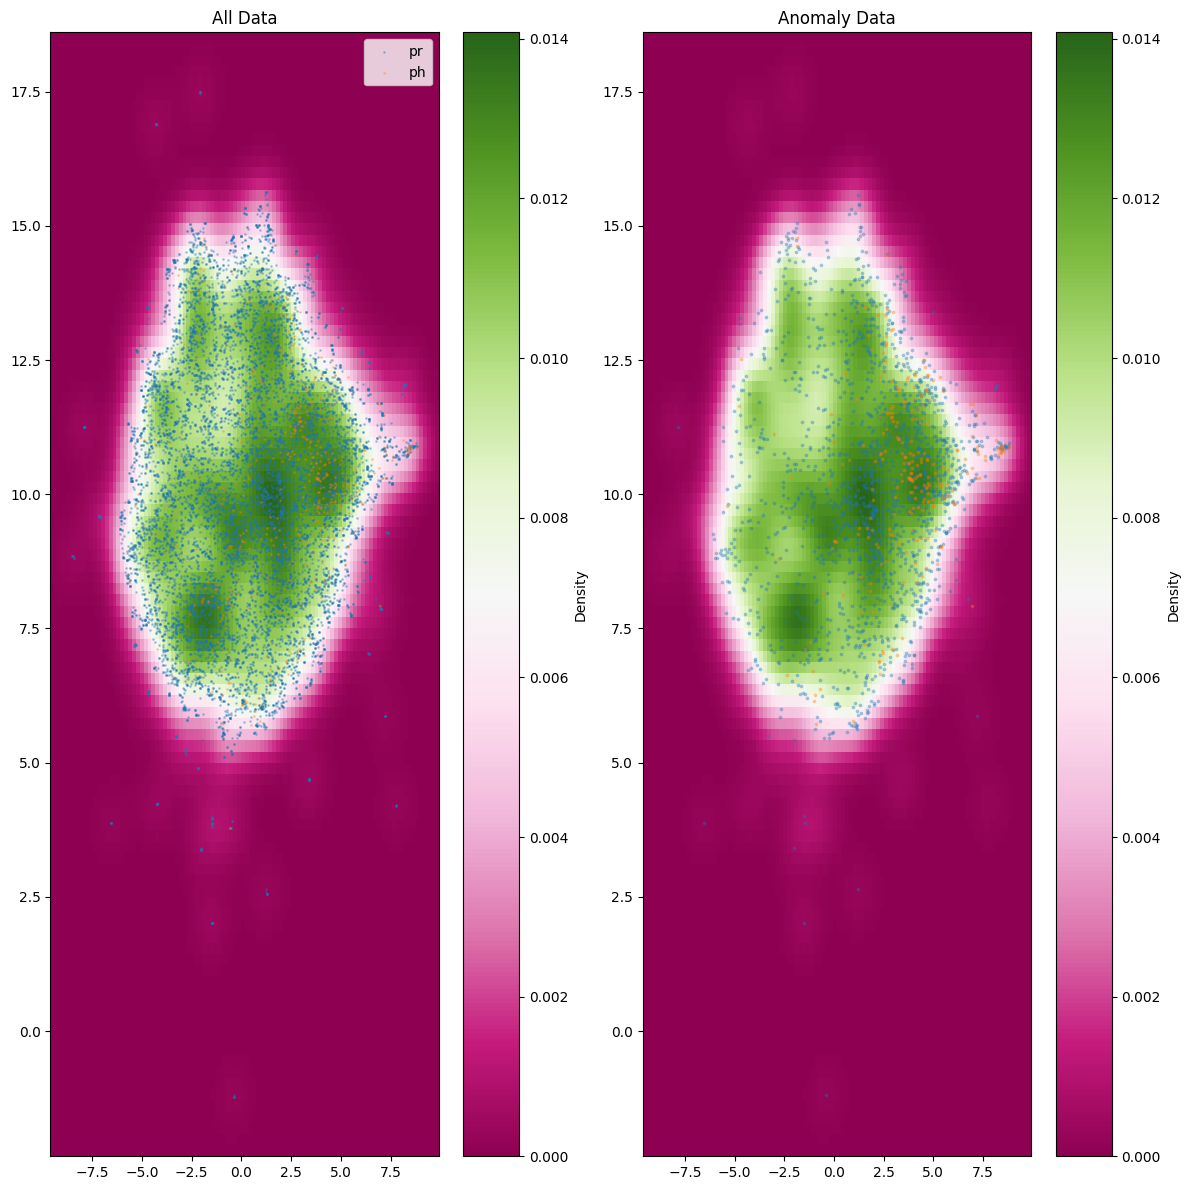

In [71]:
show_del_by_score_only_KDE_MAP(X_scaled[label_X == 0], X_scaled[label_X == 1], n_ph=1, density_ph=scores_ph, density_pr=scores_pr, th=th)

Было 
```
10440 485
1540 263
1540 263
```

СТало
```
10407 472
1509 227
1509 227
```

## по бинам анализ

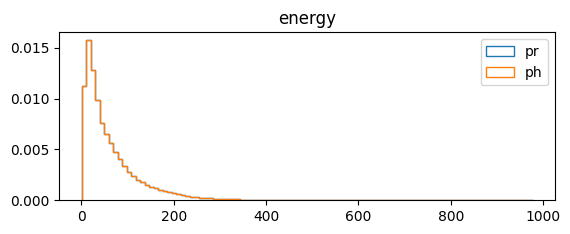

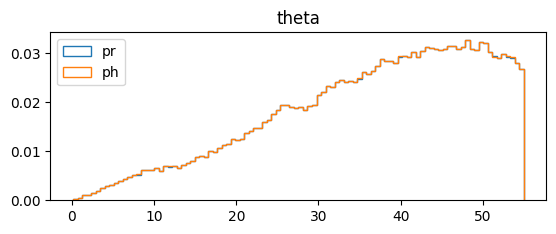

In [124]:
# plt.subplots(2,1, figsize=(10, 10))
plt.subplot(2,1,1)
plt.hist(recos_norming_pr[:,3], bins=100, label='pr', histtype='step', density=True)
plt.hist(recos_norming_photon[:,3], bins=100, label='ph', histtype='step', density=True)
plt.title('energy')
plt.legend()
plt.show()
plt.subplot(2,1,2)
plt.hist(recos_norming_pr[:,0], bins=100, label='pr', histtype='step', density=True)
plt.hist(recos_norming_photon[:,0], bins=100, label='ph', histtype='step', density=True)
plt.title('theta')
plt.legend()
plt.show()


[     0  30045  60090  90135 120180 150225 180270 210314] 8


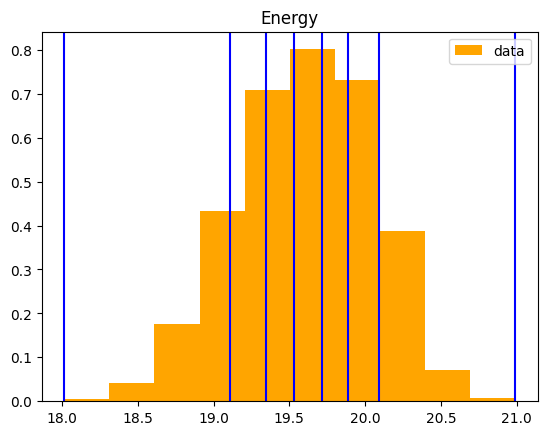

данных в одном бине 30045.0


In [125]:
Energy_pr = np.log10(recos_norming_pr[:,3])+18
Energy_photon = np.log10(recos_norming_photon[:,3])+18
indices_pr_E = np.argsort(recos_norming_pr[:,3])
indices_photon_E = np.argsort(recos_norming_photon[:,3])
num_bins = 7

indices_bin_E = np.linspace(0, len(indices_pr_E), num_bins,endpoint=False).astype(int)
indices_bin_E = np.append(indices_bin_E, len(indices_pr_E)-1)
print(indices_bin_E, len(indices_bin_E))

plt.hist(Energy_pr, density=True, label='data', color='orange')
# plt.hist(Energy_photon, density=True, label='photon')
for i in range(num_bins+1):
    v = indices_pr_E[indices_bin_E[i]]
    # plt.axvline(Energy_pr[v], color='red')
    plt.axvline(Energy_photon[v], color='blue')
plt.legend()
plt.title('Energy')
plt.show()

print(f'данных в одном бине {len(indices_pr_E)/num_bins}')

-0.44057262 -0.18435791


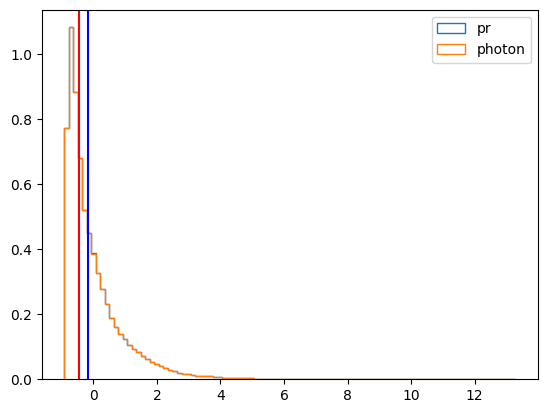

In [127]:
n_bin = 3

v_min = indices_pr_E[indices_bin_E[n_bin]]
v_max = indices_pr_E[indices_bin_E[n_bin+1]]

E_min = recos_norming_pr[:,3][v_min]
E_max = recos_norming_pr[:,3][v_max]

norm_E_min = (E_min  - mean_recos[3])/std_recos[3]
norm_E_max = (E_max  - mean_recos[3])/std_recos[3]

print(norm_E_min, norm_E_max)



plt.hist(recos_pr[:,3], bins=100, label='pr', histtype='step', density=True)
plt.hist(recos_photon[:,3], bins=100, label='photon', histtype='step', density=True)
plt.axvline(norm_E_min, color='red')
plt.axvline(norm_E_max, color='blue')
plt.legend()
plt.show()

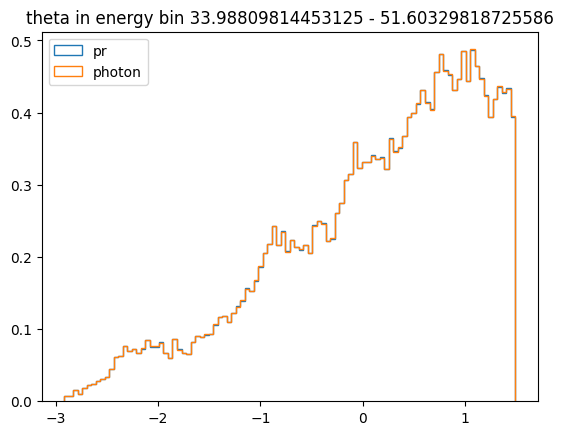

In [128]:
indexby_ener_pr = np.where(np.logical_and(recos_pr[:,3] > norm_E_min, recos_pr[:,3] < norm_E_max))[0]
indexby_ener_photon = np.where(np.logical_and(recos_photon[:,3] > norm_E_min, recos_photon[:,3] < norm_E_max))[0]

plt.hist(recos_pr[indexby_ener_pr,0], bins=100, label='pr', histtype='step', density=True)
plt.hist(recos_photon[indexby_ener_photon,0], bins=100, label='photon', histtype='step', density=True)
plt.legend()
plt.title(f'theta in energy bin {E_min} - {E_max}')
plt.show()





In [129]:
recos_pr[indexby_ener_pr,0].shape

(30044,)

[    0  4292  8584 12876 17168 21460 25752 30043] 8


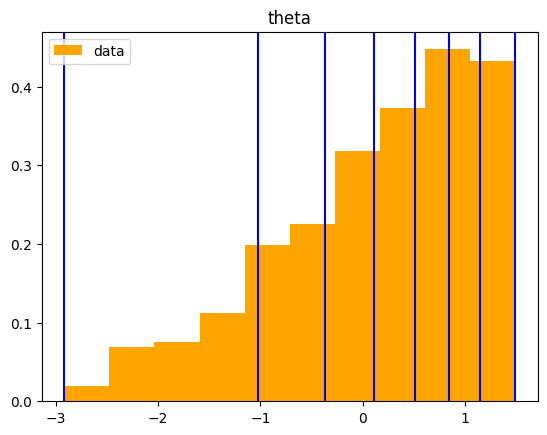

данных в одном бине 4292.0


In [130]:
indices_pr_theta = np.argsort(recos_pr[indexby_ener_pr,0])
indices_photon_theta = np.argsort(recos_photon[indexby_ener_photon,0])
num_bins = 7

indices_bin_theta = np.linspace(0, len(recos_pr[indexby_ener_pr,0]), num_bins,endpoint=False).astype(int)
indices_bin_theta = np.append(indices_bin_theta, len(recos_pr[indexby_ener_pr,0])-1)
print(indices_bin_theta, len(indices_bin_theta))

plt.hist(recos_pr[indexby_ener_pr,0], density=True, label='data', color='orange')
# plt.hist(Energy_photon, density=True, label='photon')
for i in range(num_bins+1):
    v = indices_pr_theta[indices_bin_theta[i]]
    # plt.axvline(Energy_pr[v], color='red')
    plt.axvline(recos_pr[indexby_ener_pr,0][v], color='blue')
plt.legend()
plt.title('theta')
plt.show()

print(f'данных в одном бине {len(indices_pr_theta)/num_bins}')

-0.44057262 -0.18435791 0.10912752 0.50777656


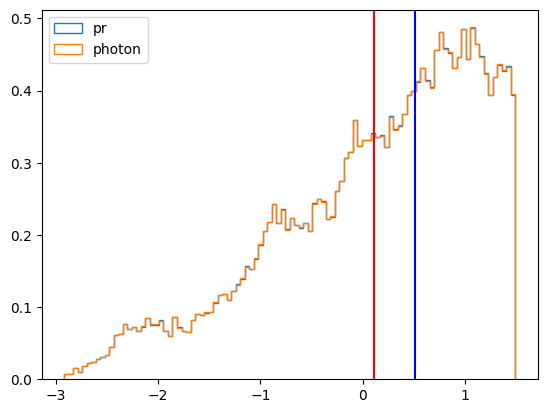

In [131]:
n_bin_theta = 3

v_min = indices_pr_theta[indices_bin_theta[n_bin_theta]]
v_max = indices_pr_theta[indices_bin_theta[n_bin_theta+1]]

theta_min = recos_pr[indexby_ener_pr,0][v_min]
theta_max = recos_pr[indexby_ener_pr,0][v_max]

norm_theta_min = theta_min#(theta_min  - mean_recos[0])/std_recos[0]
norm_theta_max = theta_max#(theta_max  - mean_recos[0])/std_recos[0]

print(norm_E_min, norm_E_max, norm_theta_min, norm_theta_max)


plt.hist(recos_pr[indexby_ener_pr,0], bins=100, label='pr', histtype='step', density=True)
plt.hist(recos_photon[indexby_ener_photon,0], bins=100, label='photon', histtype='step', density=True)
plt.axvline(norm_theta_min, color='red')
plt.axvline(norm_theta_max, color='blue')
plt.legend()
plt.show()

(210315, 15) (30044,) (4291,)


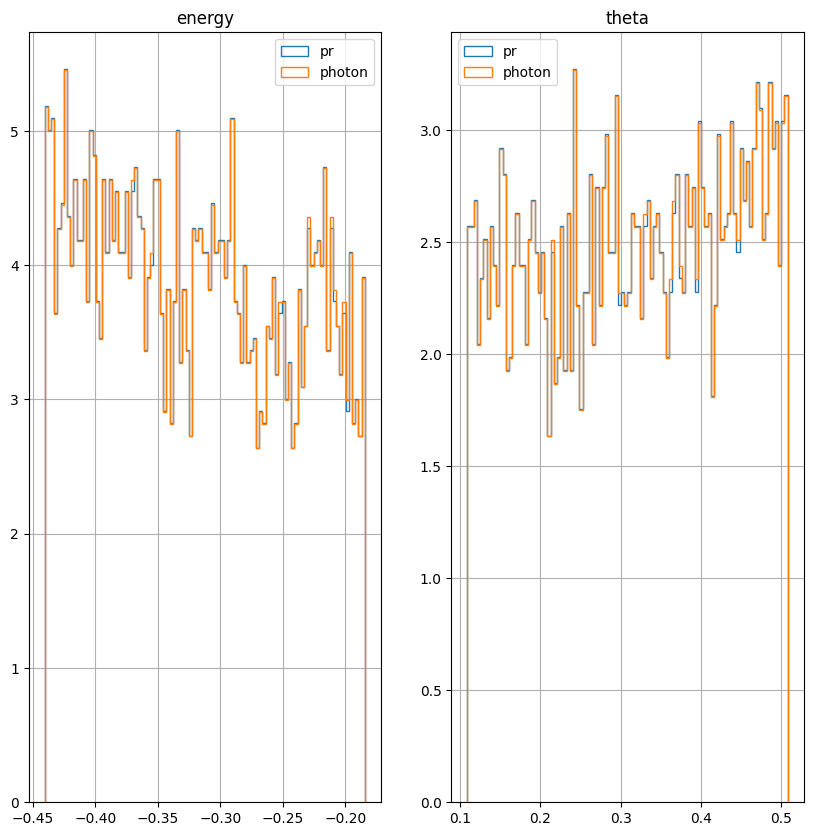

(4291,) (4299,)
0.10917559 0.5077444 0.10912752 0.50777656


In [132]:
index_for_2_bins_pr = np.where(np.logical_and(recos_pr[indexby_ener_pr,0] > norm_theta_min, recos_pr[indexby_ener_pr,0] < norm_theta_max))[0]
index_for_2_bins_photon = np.where(np.logical_and(recos_photon[indexby_ener_photon,0] > norm_theta_min, recos_photon[indexby_ener_photon,0] < norm_theta_max))[0]

index_for_2_bins_pr = indexby_ener_pr[index_for_2_bins_pr]
index_for_2_bins_photon = indexby_ener_photon[index_for_2_bins_photon]
print(recos_pr.shape, indexby_ener_pr.shape, index_for_2_bins_pr.shape)
fig, ax = plt.subplots(1,2, figsize=(10, 10))
ax[0].hist(recos_pr[index_for_2_bins_pr,3], bins=100, label='pr', histtype='step', density=True)
ax[0].hist(recos_photon[index_for_2_bins_photon,3], bins=100, label='photon', histtype='step', density=True)


ax[1].hist(recos_pr[index_for_2_bins_pr,0], bins=100, label='pr', histtype='step', density=True)
ax[1].hist(recos_photon[index_for_2_bins_photon,0], bins=100, label='photon', histtype='step', density=True)

ax[0].legend()
ax[1].legend()

ax[0].set_title('energy')
ax[1].set_title('theta')
ax[0].grid()
ax[1].grid()
plt.show()
print(recos_pr[index_for_2_bins_pr,0].shape, recos_photon[index_for_2_bins_photon,0].shape)
print(recos_pr[index_for_2_bins_pr,0].min(), recos_pr[index_for_2_bins_pr,0].max(), norm_theta_min, norm_theta_max)

In [136]:
# по бинам анализ


N = 10
recos_last = -4
bandwidth = 0.58
part = 0.1
print(f'part of data {part}')
print('pr', embading_pr.shape, 'ph', embading_photon.shape)
# cut by energy bin and theta bin
index = index_for_2_bins_pr.copy()
index_ph = index_for_2_bins_photon.copy()
index_ph = np.random.choice(index_ph, int(len(index_ph)*part))
print('index_ph', index_ph.shape, 'index', index.shape)

# without recos
feaches_pr = np.concatenate([embading_pr[index], num_det_pr[index].reshape(-1,1), recon_loss_pr[index].reshape(-1,1)], axis=1)

feaches_photon = np.concatenate([embading_photon[index_ph], num_det_photon[index_ph].reshape(-1,1), recon_loss_photon[index_ph].reshape(-1,1)], axis=1)

# add recos
feaches_pr = np.concatenate([feaches_pr, recos_pr[index, :-recos_last]], axis=1)
feaches_photon = np.concatenate([feaches_photon, recos_photon[index_ph, :-recos_last]], axis=1)


print('feaches_pr', feaches_pr.shape, 'feaches_photon', feaches_photon.shape)

print('with detecor constant',np.sum(feaches_pr[:,8] == N), np.sum(feaches_photon[:,8] == N))


part of data 0.1
pr (210315, 8) ph (210851, 8)
index_ph (429,) index (4291,)
feaches_pr (4291, 14) feaches_photon (429, 14)
with detecor constant 397 35


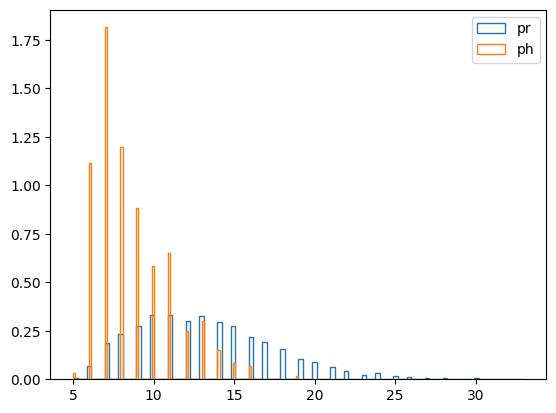

((2123,), (4291, 14), (429, 14))

In [137]:
plt.hist(feaches_pr[:,8], bins=100, label='pr', histtype='step', density=True)
plt.hist(feaches_photon[:,8], bins=100, label='ph', histtype='step', density=True)
plt.legend()
plt.show()
num_det_feaches.shape, feaches_pr.shape, feaches_photon.shape

[[ 2.82276899e-01 -3.06957185e-01  6.13448441e-01 -6.10881150e-01
   1.27034798e-01 -1.07521743e-01 -1.22371924e+00  4.84812647e-01
   1.30000000e+01  7.11033773e-03  4.46862698e-01 -8.30664784e-02
  -3.45073342e-01 -4.20215279e-01]
 [-7.29734182e-01 -1.05972745e-01  8.98605883e-01  1.17789829e+00
   1.05351675e+00 -8.58903468e-01  5.37993386e-02  1.40717298e-01
   1.70000000e+01  9.28837340e-03  2.28627563e-01 -1.34669805e+00
  -1.40255122e-02 -1.85934573e-01]
 [-1.24646568e+00 -6.38287067e-01  1.15432358e+00 -9.88465995e-02
   9.22059536e-01 -3.05995643e-01  6.69436514e-01 -1.00423253e+00
   1.80000000e+01  1.34291090e-02  1.55015677e-01 -8.61243129e-01
  -2.97209501e-01 -4.23903883e-01]
 [ 8.58165979e-01  3.65336448e-01 -2.95471728e-01 -2.28258297e-01
  -1.03493667e+00 -1.38607574e+00 -6.24120712e-01 -8.89965296e-01
   1.00000000e+01  2.86129210e-03  2.94477820e-01 -5.17341018e-01
  -2.23230749e-01 -3.47735614e-01]
 [ 9.60003495e-01 -5.12816787e-01 -1.58817935e+00  3.67598057e-01
  

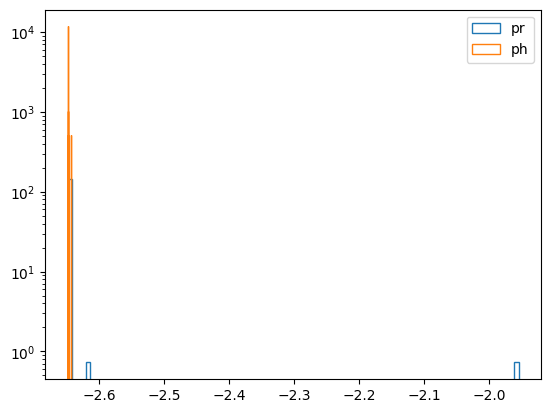

In [139]:
bandwidth = 0.3
feaches = np.concatenate([feaches_pr, feaches_photon], axis=0)

label = np.concatenate([np.zeros(len(feaches_pr)), np.ones(len(feaches_photon))])

# # shufle
shufle_index = np.random.permutation(len(feaches))
feaches = feaches[shufle_index]
label = label[shufle_index]

num_det_feaches = feaches[:,8]

print(feaches[:10], label[:10])


# X = feaches[:][num_det_feaches == N].copy()
X = np.concatenate([X[:,:8], X[:,9:]], axis=1)
print(X.shape)
# Лучше RobustScaler, чем StandardScaler, для задач с выбросами
scaler = RobustScaler()
X_scaled = scaler.fit_transform(X)
X_scaled
label_X = label[num_det_feaches == N]
print('pr',(label_X == 0).sum(), 'ph', (label_X == 1).sum())


num=100
index = np.random.randint(0, len(X_scaled), num)
kde = KernelDensity(bandwidth=bandwidth).fit(X_scaled)


scores = kde.score_samples(X_scaled[index])
label_scores = label_X[index]

scores_pr = kde.score_samples(X_scaled[label_X == 0])
scores_ph = kde.score_samples(X_scaled[label_X == 1])
print(scores_pr.mean(), scores_ph.mean())
print(scores_pr.std(), scores_ph.std())
plt.hist(scores_pr, bins=100, label='pr', histtype='step', density=True, log=True)
plt.hist(scores_ph, bins=100, label='ph', histtype='step', density=True, log=True)
plt.legend()